# **Datos Alumno**

# * **Nombre**:
# * **No control**:

#### **En esta actividad trabajarás con datos históricos del precio de mercado de la acción de alguna de las grandes compañías como Nvidia, Tesla, Google.**

Sigue los siguientes pasos para descargar los datos del problema:

    Ir a la página de Yahoo!-Finance: https://finance.yahoo.com/

En el buscador de dicha página pon las iniciales de la compañía deseada. Deberás seleccionar alguna de las siguientes compañías: AAPL, NVDA, TSLA, GOOG, AMZN o MSFT.

Seleccionar la pestaña "Historical Data".

Pulsa "Download" para descargar el archivo de datos históricos de los movimientos diarios de los últimos 5 años.



# **En esta Actividad se trabajará con los datos historicos del precio de mercado de la acción, Compañia TESLA.**

# **0 - Preparando los datos ORIGINALES**

In [ ]:
# Omitamos los Warnings por el momento:
import warnings
warnings.filterwarnings("ignore")

In [ ]:
#!pip freeze   # Si deseas verificar qué librerías y versiones ya tiene google-Colab preinstaladas,
               # en particular "prophet" que usaremos en este ejercicio.

In [1]:

#Libreria para obtener el conjunto de datos
import yfinance as yf

#Para manipular datos
import numpy as np
import pandas as pd

#Para graficar
import matplotlib.pyplot as plt

#Error cuadratico medio
from sklearn.metrics import mean_squared_error
import math

#Para aplicar escalamiento de datos [0,1]
from sklearn.preprocessing import MinMaxScaler

from prophet import Prophet
from statsmodels.graphics.tsaplots import month_plot, quarter_plot
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf   # gráficos de autocorrelación

#A) **Descargar el archivo de datos históricos de los movimientos diarios de los últimos 5 años.**

In [2]:


#Escribimos las iniciales de la compañia con la que deseemos trabajar. En esta ocasión trabajare con Tesla

ticker_symbol = 'NVDA'                           # selecciona las iniciales de la compañía deseada.
#data = yf.download(ticker_symbol, period='5y')   # Se indica el período de 5 años y descargamos.

#segunda forma, ya que no se esta incluyendo la columna de date en el df descargado
#definirn el rango de fechas a descargar (5 años)
start_date = "2021-11-23"
end_date = "2026-11-23"

#convierte a dataframe
#auto_adjust=False para incluir adj close
df = yf.download(ticker_symbol, start=start_date, end=end_date, auto_adjust=False)   #header=2 para que no tome en cuenta los 2 primeros renglones, ya que estan vacios
#df.columns=['Date','Adj Close','Close','High','Low','Open','Volume'] #Se agrega columna Date


#esta cosa si es importante, sirve para quitar el multiindex, osea solo quede una fila de encabezados
if isinstance(df.columns, pd.MultiIndex):
    df.columns = df.columns.get_level_values(0)
df.columns.name = None
df =df.reset_index()

df.head()

[*********************100%***********************]  1 of 1 completed


,Date,Adj Close,Close,High,Low,Open,Volume
0,2021-11-23,31.606785,31.746000,32.360001,30.879999,31.535000,532163000
1,2021-11-24,32.530712,32.674000,32.855000,30.927999,31.461000,435162000
2,2021-11-26,31.364849,31.503000,32.709999,31.350000,32.599998,283069000
3,2021-11-29,33.229641,33.375999,33.411999,32.035999,32.366001,454964000
4,2021-11-30,32.532700,32.675999,33.353001,31.864000,33.168999,622066000


In [3]:
df.info()   # Verifica detalles del conjunto de datos a utilizar
            # El dataframe cuenta con 1258 registros
            # 7 columnas las cuales son: Date, Adj close, Close, High, Low, Open, Volume
            # Variable Date, tipo Object -> se cambiará a tipo Fecha

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1254 entries, 0 to 1253
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   Date       1254 non-null   datetime64[ns]
 1   Adj Close  1254 non-null   float64       
 2   Close      1254 non-null   float64       
 3   High       1254 non-null   float64       
 4   Low        1254 non-null   float64       
 5   Open       1254 non-null   float64       
 6   Volume     1254 non-null   int64         
dtypes: datetime64[ns](1), float64(5), int64(1)
memory usage: 68.7 KB


#**B)Utiliza solamente los datos de la columna "Adj Close" en esta actividad.**

In [4]:
# Renombremos de manera estándar las columnas de fechas y valores de la
# serie de tiempo, donde además la fecha la trasnformamos a tipo datetime:

df = df.drop(columns=['Close','High','Low','Open','Volume']) #Elimina columnas que no se requieren
df = df.rename(columns={'Adj Close':'y'})                    #Columna Adj Close, renombramos por y
df['Date'] = pd.to_datetime(df['Date'])                      #Convertimos variable Date de tipo Object a Datetime
df.head()                                                    #Muestra primeros 5 registros para visualizar el cambio

,Date,y
0,2021-11-23,31.606785
1,2021-11-24,32.530712
2,2021-11-26,31.364849
3,2021-11-29,33.229641
4,2021-11-30,32.532700


In [5]:
df.info() #Creación de un nuevo df, el cual consta de 2 columnas, las cuales son:
          #Variable Date -> de tipo datetime64, nos ayuda a representar un rango de fechas muy amplio con presición nanosegundos
          #Variable 'Adj Close' -> fue renombrada por 'y' de tipo flotante,

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1254 entries, 0 to 1253
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   Date    1254 non-null   datetime64[ns]
 1   y       1254 non-null   float64       
dtypes: datetime64[ns](1), float64(1)
memory usage: 19.7 KB


En particular datetime64[ns] nos ayuda a representar un rango de fechas muy amplio con precisión de nanosegundos.

### **Agreguemos los ajustes usuales en Series de tiempo:**

In [6]:
# Hagamos una copia del DataFrame df con índices temporales:

df_temp = df.copy()                     #Genera copia del df originar en nueva variable temporal de nombre: df_temp
df_temp.set_index('Date', inplace=True) #se establece como indice Variable Date,
                                        #parametro inplace=True, es para guardar los cambios
df_temp.head()                          #visualizar los cambios

,y
Date,
2021-11-23,31.606785
2021-11-24,32.530712
2021-11-26,31.364849
2021-11-29,33.229641
2021-11-30,32.532700


In [7]:
#Muestra información sobre numero total de registros y columnas como estan conformados el df original (df) y el df temporal (df_temp)

print("DataFrame Original:\n ")
print(df.shape)      #Conformado por 1258 registros y 2 columnas (Date, y)

print("\nDataFrame Temporal:\n")
print(df_temp.shape) #Conformado por 1258 regsitros y 1 columna (y), Variable Date pase a ser indice

DataFrame Original:
 
(1254, 2)

DataFrame Temporal:

(1254, 1)


https://pandas.pydata.org/docs/reference/api/pandas.DatetimeIndex.html

In [8]:
# Ajustemos la frecuencia de los índices, para que el modelo tenga información del período en que
# se encuentran los datos:

df_temp.index =df_temp.index.tz_localize(None) #Para quitar zona horaria
df_temp.index


DatetimeIndex(['2021-11-23', '2021-11-24', '2021-11-26', '2021-11-29',
               '2021-11-30', '2021-12-01', '2021-12-02', '2021-12-03',
               '2021-12-06', '2021-12-07',
               ...
               '2026-11-09', '2026-11-10', '2026-11-11', '2026-11-12',
               '2026-11-13', '2026-11-16', '2026-11-17', '2026-11-18',
               '2026-11-19', '2026-11-20'],
              dtype='datetime64[ns]', name='Date', length=1254, freq=None)

-----------------------------------------------------------------------------
**Se puede observar que la ejecución se esta línea de código indica 'freq=None', por lo cual tendremos que definir un tipo de frecuencia (ya sea por dias, meses, años). La cual se definirá en el siguiente segmento de código que se muestra a continuación:**

-----------------------------------------------------------------------------

Para las opciones de "freq" ver la tabla que viene en esta liga:

https://pandas.pydata.org/pandas-docs/stable/user_guide/timeseries.html#offset-aliases

In [9]:
# Especifiquemos entonces que nuestros datos están registrados con una frecuencia mensual
# al inicio del mes (cada día 01 de cada mes):

df_temp = df_temp.resample('B').asfreq()#Define frecuencia B -> frecuencia del día de actividad
df_temp.index

DatetimeIndex(['2021-11-23', '2021-11-24', '2021-11-25', '2021-11-26',
               '2021-11-29', '2021-11-30', '2021-12-01', '2021-12-02',
               '2021-12-03', '2021-12-06',
               ...
               '2026-11-09', '2026-11-10', '2026-11-11', '2026-11-12',
               '2026-11-13', '2026-11-16', '2026-11-17', '2026-11-18',
               '2026-11-19', '2026-11-20'],
              dtype='datetime64[ns]', name='Date', length=1304, freq='B')

#**C)Investiga el significado de esta columna Adj-Close e inclúyelo en tu reporte del Jupyter-Notebook.**

###Investigación

-------------------------------------------------------------------------
¿Qué es el Cierre Ajustado?

Adj Close es una columna Clave dentro de los datos historicos . El **Precio Ajustado de cierre**, se apoya de dividendos y splist de acciones, que afectan el precio de la acción.

Es una versión ajustada del Precio de Cierre de una acción, después de los ajustes para todas las distribuciones de splits y dividendos aplicables, los cuales se definen a continuación:

 * **Dividendos**, Aqui es cuando la empresa distribuye dividendos a sus accionistas. El dividendo se "resta" del precio de la acción para representar el valor real de la acción después del pago realizado.

* **Splits(Divisiones de Acciones)**, Aqui es cuando el precio de la acción se ajusta para reflejar la nueva cantiad de acciones en circulación. Aumenta el número de acciones de circulación, pero la capitalización no cambia

##Importancia del Adj Close

El Adj Close, es muy importante ya que gracias a el se puede visualizar de mejor la manera la evolución del valor de la acción que se ha tenido a lo largo del tiempo. Siendo muy útil al momenteo de realizar análisis de rendimiento y asi lograr obtener una visipon más clara de cómo se ha comportado una acción dentro del mercado por un periodo de tiempo

De igual manera también es muy útil para realizar cálculos más precisos, si se desea cálcular el rendimiento total de una acción o retornos de una inversión en un cierto periodo, ya que por otro lado si se hace uso unicamente de "close" sin el ajuste, puede existir sesgo en el análisis.

--------------------------------------------------------------------

#**D)Divide los datos en Train y Test, donde Test serán los últimos 20 precios de mercado de la compañía que seleccionaste**

In [10]:
df_temp=df_temp.ffill() #para rellenar datos faltantes NaN
datos_nan=df_temp[df_temp.isna().any(axis=1)] #para verificar existencia datos faltantes
#print(datos_nan)

In [11]:
# Particionemos en entrenamiento y prueba como DataFrames de Pandas:
train = df_temp.iloc[0:-20,:] # Selecciona todos los registros, excepto últimos 20
test = df_temp.iloc[-20:,:]   # Seleccionamos los datos del últimoS 20 registros para predicción de Test.

In [12]:
test.head()  #muestra registros del test

,y
Date,
2026-10-26,216.000000
2026-10-27,217.940002
2026-10-28,215.380005
2026-10-29,213.660004
2026-10-30,204.639999


In [13]:
datos_nan=train[train.isna().any(axis=1)]
print(datos_nan) #verificamos que no existan datos faltantes NaN en Entrenamiento (train)

datos_nan=test[test.isna().any(axis=1)]
print(datos_nan) #verificamos que no exista datos faltantes NaN en Pueba (test)

Empty DataFrame
Columns: [y]
Index: []
Empty DataFrame
Columns: [y]
Index: []


In [14]:
train.shape #Entrenamiento conformado por 1285 registros y 1 columna

(1284, 1)

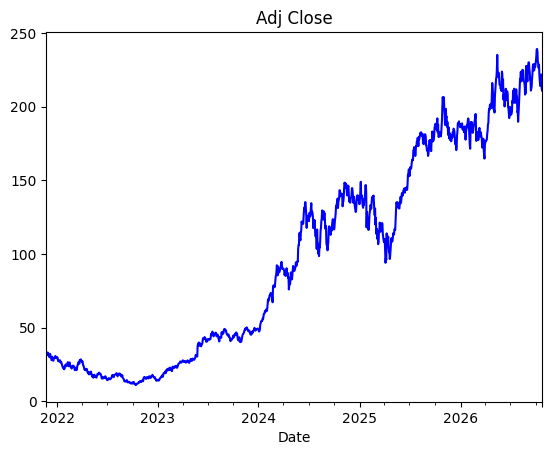

In [15]:
# Gráfico con la periodicidad anual:
train['y'].plot(title='Adj Close', style='-b')
plt.show()

## <font color=orange>**Escriba su Interpretación de la gráfica**</font>





## <font color=orange>**De este gráfico podemos observar:**

1.    Durante el 2022 tiene una tendencia hacia decrecer que llega en el punto mas bajo a finales de año

2.    En 2023, el precio comienza a recuperarse y muestra un crecimiento progresivo.

3. Durante 2024, se observa un aumento significativo en el precio, pasando aproximadamente de 50 a 140 puntos

4. Entre 2025 y 2026, el precio presenta constantes subidas y bajadas, lo que refleja cierta volatilidad en el comportamiento de las acciones.

5.   2026 el precio alcanza valores cercanos a 240 puntos, mostrando un crecimiento considerable en comparación con los años anteriores.



# **1 - Modelo ingenuo (Baseline / Persistance / Naive model)**

# **DATOS ORIGINALES**

*   El modelo ingenuo simplemente **hace la predicción del siguiente período, repitiendo el valor del último período**.

*   Este modelo se utiliza en general como punto de partida **para comparar todos los demás**.

*   Utilicemos el error RMSE (Raíz del Error Cuadrático Medio) como medida del desempeño de nuestros modelos a obtener.

In [16]:
test['y'].values #muestra valores del conjunto test en arreglo

array([216.        , 217.94000244, 215.38000488, 213.66000366,
       204.63999939, 202.05999756, 206.69000244, 200.13000488,
       181.6000061 , 186.63999939, 178.66999817, 168.88999939,
       173.72999573, 166.19000244, 162.8500061 , 156.13999939,
       155.46000671, 150.96000671, 145.97999573, 125.52999878])

In [17]:
history = [x for x in train['y'].values]   # Definimos "history" donde de manera incremental se irán agregando registros mensuales.
predictions = list()    # Lista que contendrá las predicciones del modelo ingenuo.

for i in range(len(test['y'])):
  # Obtenemos las predicciones:
  yhat = history[-1]   # La primera vez, tomamos el último dato del Train, en las siguientes, se van agregando los datos de Test.
  predictions.append(yhat)

  # Observaciones-registros reales:
  obs = test.iloc[i]['y']   # Ahora vamos tomando los datos de Test.
  history.append(obs)  # Vamos agregando a "history" (que ya tiene todo los de Train) en cada iteración, un dato más de los de Test.
  print('>Esperado-real = %3d, Predicción = %.3f' % (obs, yhat))


# Calculamos la raíz del error cuadrático medio (RMSE):
rmse = np.sqrt(mean_squared_error(test['y'].values, predictions))
print('\nError-Modelo-Naive: RMSE: %.3f' % rmse)

>Esperado-real = 216, Predicción = 210.960
>Esperado-real = 217, Predicción = 216.000
>Esperado-real = 215, Predicción = 217.940
>Esperado-real = 213, Predicción = 215.380
>Esperado-real = 204, Predicción = 213.660
>Esperado-real = 202, Predicción = 204.640
>Esperado-real = 206, Predicción = 202.060
>Esperado-real = 200, Predicción = 206.690
>Esperado-real = 181, Predicción = 200.130
>Esperado-real = 186, Predicción = 181.600
>Esperado-real = 178, Predicción = 186.640
>Esperado-real = 168, Predicción = 178.670
>Esperado-real = 173, Predicción = 168.890
>Esperado-real = 166, Predicción = 173.730
>Esperado-real = 162, Predicción = 166.190
>Esperado-real = 156, Predicción = 162.850
>Esperado-real = 155, Predicción = 156.140
>Esperado-real = 150, Predicción = 155.460
>Esperado-real = 145, Predicción = 150.960
>Esperado-real = 125, Predicción = 145.980

Error-Modelo-Naive: RMSE: 8.122


----------------------------------------------------------------------------
## <font color=orange>**Interpretación**

Se nota que las predicciones aciertan con los valores reales en ciertos lapsos, sobre todo cuando los cambios en precios resulta ser mínimos.A medida que avanzan los registros de prueba (Test), los valores reales muestran una disminución considerable, pasando de 216 hasta 125.El modelo presenta dificultades para anticipar cambios bruscos, ya que únicamente utiliza el último valor real como referencia para predecir el siguiente.Se obtuvo un RMSE de 8.122, lo que indica que las predicciones tienen un error promedio cuadrático de aproximadamente 8.122 unidades respecto a los valores reales.

-----------------------------------------------------------------------------

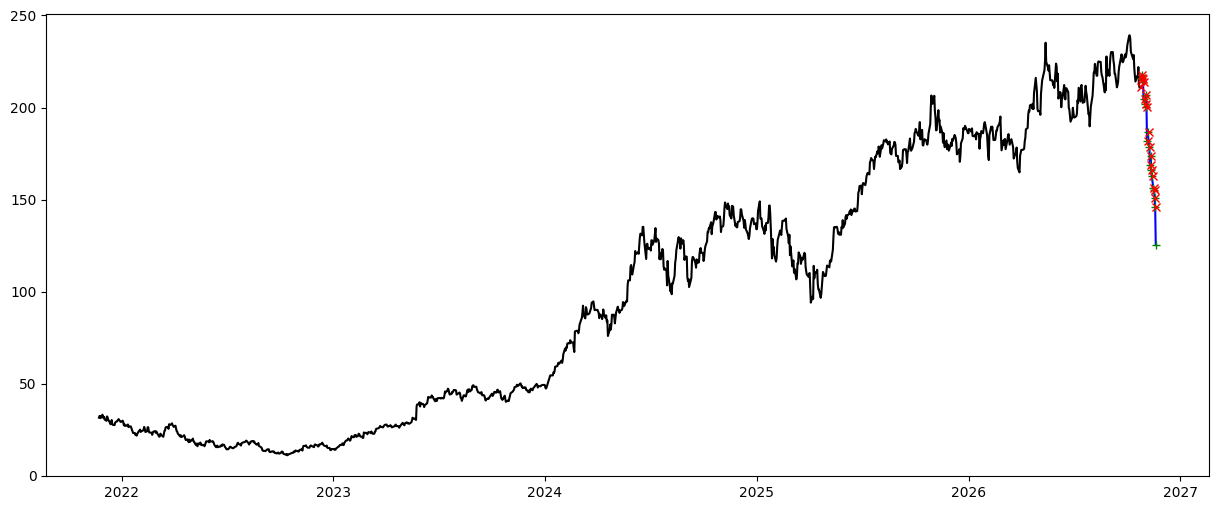

In [18]:
# Grafiquemos los resultados:

fig, ax = plt.subplots(figsize=(15, 6))
ax = plt.plot(train['y'], '-k')   # Datos de entrenamiento (los históricos).
ax = plt.plot(test['y'], '-b')    # Datos de prueba reales (los últimos 20 registros a predecir).
ax = plt.plot(test['y'],'+g')
ax = plt.plot(test.index, predictions, 'xr')  # Predicciones del modelo ingenuo.

#Verdes son los datos reales
#rojos son las predicciones

### <font color=orange>**Interpretación Gráfica.**

----------------------------------------------------------------------------
La gráfica demuestra como el modelo Naive intenta predecir los veinte registros finales tomando el valor anterior por referencia. Se puede observar que las predicciones en rojo siguen casi de cerca a los valores reales de color verde, aunque existen diferencias marcadas cuando ocurre una caída importante en los precios

----------------------------------------------------------------------------

# **2 - Modelo ARIMA**

# **DATOS ORIGINALES**

### **Análisis preliminar para obtener información de la serie de tiempo y construir el modelo ARIMA(p,d,q).**

*   **AR (AutoRegresivo):** El modelo se basa en la **relación entre un valor actual y sus valores pasados.**

*   **I (Integrado):** Se refiere a la diferenciación de la serie para hacerla estacionaria, es decir, eliminar tendencias y patrones cíclicos.

*   **MA (Media Móvil):** Usa el error de los valores pasados (las desviaciones entre valores predichos y observados) para corregir el valor actual.

##### **Ahora veamos el gráfico de descomposición de la serie de tiempo en sus componentes de tendencia (trend), estacionalidad (stationality) y residual (residual).**

/tmp/ipykernel_11886/2564742500.py:3: FutureWarning: 'Q' is deprecated and will be removed in a future version, please use 'QE' instead.
  decomposition = seasonal_decompose(train['y'].resample('Q').mean(), model='multiplicative')  # <<<---- Observa que el modelo es multiplicativo


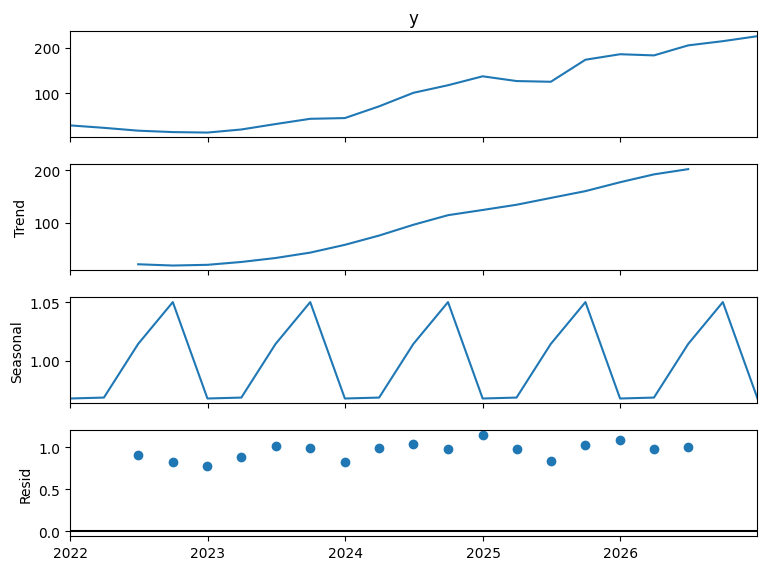

In [19]:
# Gráficos de descomposición estacional:
#parametro Q indica año
decomposition = seasonal_decompose(train['y'].resample('Q').mean(), model='multiplicative')  # <<<---- Observa que el modelo es multiplicativo
fig = decomposition.plot()
fig.set_size_inches(8,6)
plt.show()

# <font color=orange>**Interpretación de cada una de las Gráficas**

-----------------------------------------------------------------------------

En esta gráfica nos desgloza 4 gráficas:

1. **Gráfica Original**, Muestra el comportamiento general de los datos desde 2022 hasta 2026. Se observa una tendencia creciente, aunque existen algunas variaciones durante el periodo.

2. **Tendencia (Trend)**, Se observa un crecimiento progresivo a partir de 2023, lo que indica que los valores han aumentado con el paso del tiempo.

3. **Estacional (Seasonal)**, Presenta un patrón repetitivo que se mantiene a lo largo de los años, con pequeñas variaciones que indican un comportamiento estacional.

4. **Residuos (Resid)**, Representan las variaciones que no son explicadas por la tendencia ni la estacionalidad. En este caso, los valores se mantienen relativamente cercanos a 1.

-----------------------------------------------------------------------------

##### **Veamos ahora estos dos gráficos que nos hablan si tenemos algún tipo de estacionalidad (i.e., periodicidad). En particular, mensual o trimestral:**

/tmp/ipykernel_11886/1354699239.py:2: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  fig = month_plot(train['y'].resample('M').mean(), ylabel='Adj Close')


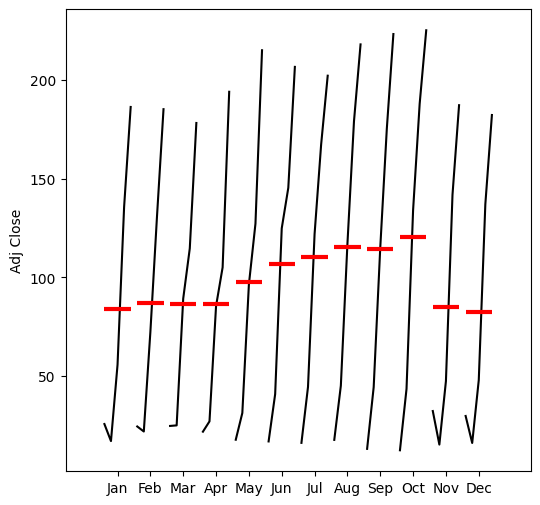

In [20]:
# Gráfica para detección de estacionalidad mensual:
fig = month_plot(train['y'].resample('M').mean(), ylabel='Adj Close')
fig.set_size_inches(6,6)
plt.show()

# <font color=orange>**Interpretación Gráfica**

-----------------------------------------------------------------------------
La gráfica revela un comportamiento estacional claro en los precios, el cual varia segun cada mes. Los precios promedio mas altos se observan entre junio y octubre, mientras que en noviembre y diciembre se nota una baja. Esto indica que existen meses con valores mas elevados, aunque hay una tendencia general de crecimiento a lo largo del periodo.



----------------------------------------------------------------------------

/tmp/ipykernel_11886/2088399157.py:2: FutureWarning: 'Q' is deprecated and will be removed in a future version, please use 'QE' instead.
  fig = quarter_plot(train['y'].resample('Q').mean(), ylabel='Adj Close')


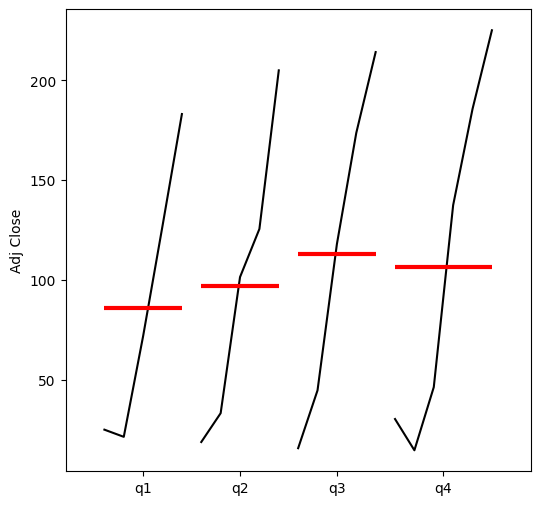

In [21]:
# Si queremos graficar y detectar estacionalidad trimestral:
fig = quarter_plot(train['y'].resample('Q').mean(), ylabel='Adj Close')
fig.set_size_inches(6,6)
plt.show()

# <font color=orange>**Interpretación Gráfica**

----------------------------------------------------------------------------
Se nota que el tercer trimestre tiene los valores promedio más altos, viniendo después el cuarto, y el primero es el que menos registra. Además, los precios va subiendo bastante con el paso de los años. Aunque, es necesario quitar la tendencia para ver si esa diferencias estacionales se mantienen constantes.



----------------------------------------------------------------------------

### **Gráficos de Autocorrelación (ACF) y Autocorrelación Parcial (PACF)**

*   Los gráficos de Autocorrelación miden la correlación entre la serie de tiempo y una versión rezagada de sí misma.

*   Este tipo de correlaciones de una serie de tiempo consigo misma son llamadas "autocorrelaciones" o "correlaciones seriales".

*   En el eje horizontal se muestra el valor del desfazamiento (lag) y en el eje vertical el valor de correlación de la serie desfazada y la original.

*   El cono sombreado indica intervalos de confianza de la correlación, con un 95% de confianza de manera predeterminada.

*   Que existan autocorrelaciones significativas en estos gráficos nos habla de que la serie de tiempo no es aleatoria.

*   En estos dos gráficos (llamados en inglés "pollipop plots") hay que determinar cuántos de estos lollipops están afuera del intervalo de confianza (sin contar el inicial) antes de que entre el siguiente a la zona celeste?

*   **Gráfico ACF:** Muestra la correlación total entre la serie y sus retardos, incluyendo efectos directos e indirectos.

*   **Gráfico PACF:** Muestra la correlación directa entre la serie y sus retardos, eliminando los efectos de los retardos intermedios.

/tmp/ipykernel_11886/4037861421.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  train['y'] = train['y'].ffill() ##Rellenan campos que estan NaN


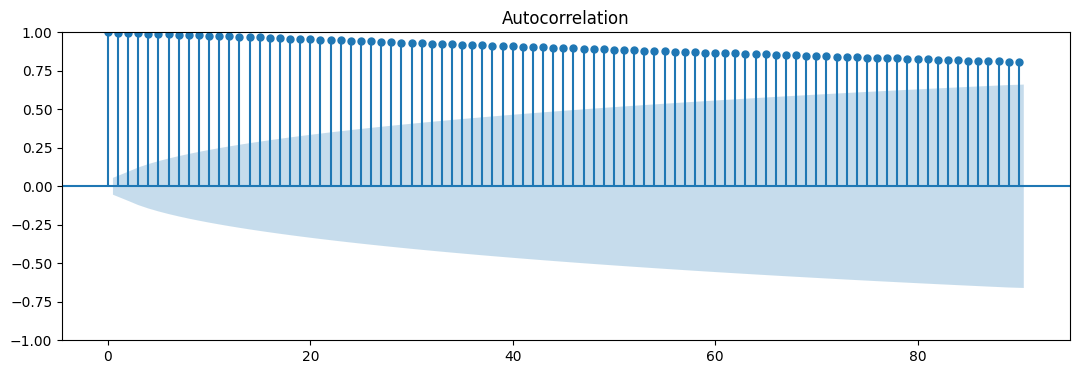

In [22]:
# Gráfico de Autocorrelación (ACF: Auto-Correlation-Function)
train['y'] = train['y'].ffill() ##Rellenan campos que estan NaN
fig,ax = plt.subplots(figsize = (13,4))
plot_acf(train['y'], lags=90, ax=ax)   # Eliges el número de unidades (meses) desfasadas. El número de "lags" es el número
plt.show()

# <font color=orange>**Intepretación Gráfica Autocorrelación (ACF)**

-----------------------------------------------------------------------------
La gráfica exhibe una autocorrelación positiva bastante elevada, demostrando que los datos de ahora se relacionan mucho con los pasados. Es evidente que la correlación decae con lentitud según suben los desfases, aunque esta se mantiene alta a lo largo de todo el periodo.



-----------------------------------------------------------------------------

El gráfico inicia con desfase (lag) de 0, lo cual es la correlación de la serie de tiempo consigo misma, la cual es 1.

Posteriormente se muestran las correlaciones de la serie de tiempo original, con la serie desfasada "q" lugares hacia atrás, es decir, de orden "q" en la componente MA de ARIMA(p,d,q).

**El gráfico ACF nos dice en primera instancia que la componente MA de ARIMA(p,d,q) tiene un grado "q" de 13 (en la práctica se puede buscar de 0 a 13).**

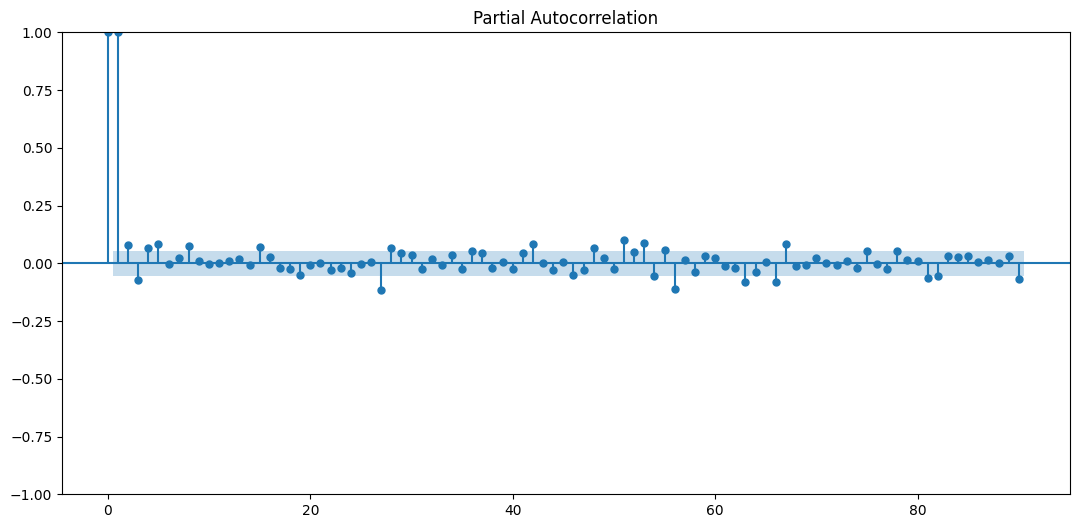

In [23]:
# Gráfico de Autocorrelación Parcial (PACF):
fig, ax = plt.subplots(figsize = (13,6))
plot_pacf(train['y'], lags = 90, ax = ax, method="ols")   # ols: regression of time series on lags of it an on constant. predetrminado method="ywm"
plt.show()

# <font color=orange>**Interpretación Gráfica Partial Autoccorelation (PACF)**

----------------------------------------------------------------------------

El gráfico de autocorrelación parcial (PACF) de la serie train['y'] hasta 90 rezagos, estimado por MCO (ols), muestra un valor de $1.0$ en el rezago 0 (consigo misma) y un valor muy alto cercano a $1.0$ en el rezago 1, lo que indica fuerte persistencia o posible no estacionariedad. A partir del rezago 2, la mayoría de los valores se mantienen cerca de cero

----------------------------------------------------------------------------

* PACF también inicia con la correlación de la serie de tiempo consigo misma, por ello el valor de 1.

*   **De este gráfico podemos observar que la componente AR de ARIMA(p,d,q) tiene grado p=3 o tal vez 5 (en la práctica se puede probar de 0 a 5.)**

##### Existe un buen número de librerías para el caso de pronósticos con los modelos ARIMA-SARIMA. Usaremos en este ejercicio la de Statsmodels, cuya documentación encuentras en la siguiente liga:

https://www.statsmodels.org/stable/generated/statsmodels.tsa.arima.model.ARIMA.html

In [24]:
from statsmodels.tsa.arima.model import ARIMA

In [25]:
# Lo primero es para quitar la estacionalidad y transformar un problema
# de tipo no-estacionario (SARIMA) en uno estacionario (ARIMA):

# Diferencia de datos consecutivos en el tiempo
# y podemos ahora usar ARIMA:
def difference(dataset, interval=1):
  diff = list()

  for i in range(interval, len(dataset)):
    value = dataset[i] - dataset[i - interval]
    diff.append(value)

  return np.array(diff)



# Invierte las diferencias anteriores, es decir, nos regresa la estacionalidad:
def inverse_difference(history, yhat, interval=1):
  return yhat + history[-interval]


In [26]:
# Definamos la siguiente lista de registros de pasajeros en el tiempo:
history = [x for x in train.loc[:,'y'].values]   # train-ndarray : columna solo con los registros de pasajeros "y".
                               # history-list : lista con los datos del train.

predictions = list()   # Para incluir las predicciones que vaya generando el modelo.

for i in range(len(test['y'])):
  #
  months_in_year = 12
  diff = difference(history, months_in_year)    # diff-list: lista de los datos de diferencias para transformar SARIMA en ARIMA.

  # Generamos el modelo.    (p,d,q)  p->valor definido en gráfica partial autocorrelation  d->Estacionaria  q->valor definido en grafica autocorrelacion
  model = ARIMA(diff, order=(1,0,13),) # Si aplicamos diff, entonces d=0 es aplicable.
  model_fit = model.fit(method_kwargs={'maxiter':300})  # Aumentar las iteraciones para evitar el WarningConvergence.

  yhat = model_fit.forecast()[0]   # prediccions (yhat) de cada registro, es un solo número flotante.
  yhat = inverse_difference(history, yhat, months_in_year)    # El "history" sigue siendo la lista de arriba.
                                                              # El nuevo "yhat" es cada un nuevo valor (float) de predicción.
  predictions.append(yhat)  # predictions-list : lista que se va incrementando al ir agregando cada predicción nueva.

  # Observaciones-reales:
  obs = test.iloc[i]['y']   #  cada dato es un flotante.
  history.append(obs)   #  history-list : se va incrementado a partir del Train con los registros-observaciones reales.

  print('>Esperado-real = %3d, Predicción = %.3f' % (obs, yhat))

# Error RMSE:
rmse = np.sqrt(mean_squared_error(test['y'].values, predictions))
print('\nError-Modelo-ARIMA: RMSE: %.3f' % rmse)

>Esperado-real = 216, Predicción = 211.319
>Esperado-real = 217, Predicción = 215.556
>Esperado-real = 215, Predicción = 217.054
>Esperado-real = 213, Predicción = 216.300
>Esperado-real = 204, Predicción = 213.675
>Esperado-real = 202, Predicción = 205.168
>Esperado-real = 206, Predicción = 203.303
>Esperado-real = 200, Predicción = 207.214
>Esperado-real = 181, Predicción = 201.987
>Esperado-real = 186, Predicción = 183.795
>Esperado-real = 178, Predicción = 187.854
>Esperado-real = 168, Predicción = 179.770
>Esperado-real = 173, Predicción = 169.812
>Esperado-real = 166, Predicción = 173.573
>Esperado-real = 162, Predicción = 166.386
>Esperado-real = 156, Predicción = 164.002
>Esperado-real = 155, Predicción = 156.390
>Esperado-real = 150, Predicción = 154.834
>Esperado-real = 145, Predicción = 151.949
>Esperado-real = 125, Predicción = 146.575

Error-Modelo-ARIMA: RMSE: 8.530


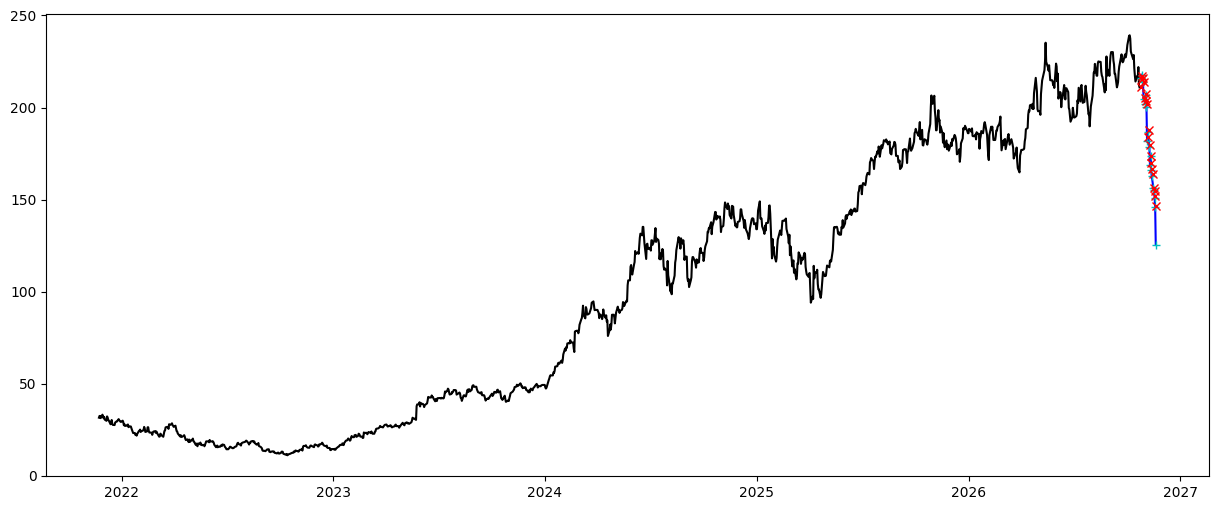

In [27]:
# Veamos su gráfico de ARIMA:
fig, ax = plt.subplots(figsize=(15, 6))
ax = plt.plot(train['y'], '-k')
ax = plt.plot(test['y'], '-b')
ax = plt.plot(test['y'], '+c')
ax = plt.plot(test.index, predictions, 'xr')

# <font color=orange>**Interpretación Gráfica ARIMA**

-----------------------------------------------------------------------------

La gráfica evidencia cómo el modelo hace predicciones sobre los últimos registros de la serie. Observamos que mientras los valores históricos muestran una tendencia creciente, las predicciones marcadas en rojo caen bastante. Aunque el modelo logra aproximarse al comportamiento inicial de los datos, tiene dificultad para anticipar correctamente la baja en los precios.


----------------------------------------------------------------------------



# **3 - Modelo Facebook-Meta-Prophet**

# **DATOS ORIGINALES**

#### **En la liga del modelo Facebook-Prophet puedes encontrar mucho más información, además de la documentación correspondiente:**

https://facebook.github.io/prophet/

In [28]:
df_temp.head() #verificar que el df_temp este en formato correcto

,y
Date,
2021-11-23,31.606785
2021-11-24,32.530712
2021-11-25,32.530712
2021-11-26,31.364849
2021-11-29,33.229641


In [29]:
# Prophet requiere que la entrada sean dos columnas, llamadas "ds" y "y".
# Les dmos esta forma usando el DataFrame "df" inicial:
df_temp = df_temp.reset_index() #reseta el indice
df_temp = df_temp.rename(columns={'Date': 'ds'}) #renombra columna 'Date' como 'ds'
df_temp.head()


,ds,y
0,2021-11-23,31.606785
1,2021-11-24,32.530712
2,2021-11-25,32.530712
3,2021-11-26,31.364849
4,2021-11-29,33.229641


In [30]:
train =df_temp.iloc[0:-20,:] #particion Entrenamiento, todo el conjunto excepto últimos 20
test = df_temp.iloc[-20:,:]  #particion Prueba, solo ultimos 20 registros de df_temp

In [31]:
# Aplicamos el modelo Facebbok-Prophet a nuestros datos:

model = Prophet(seasonality_mode='multiplicative', #se especifica el modo multiplicativo que se definio en los modelos anteriores
                yearly_seasonality=True,       #periodo anual Verdadero
                changepoint_prior_scale=10.,   # Controla la flexibilidad de la componente Trend, mayor valor mayores fluctuaciones.
                seasonality_prior_scale=30)    # Controla la estacionalidad, mayor el valor, mayor flexibilidad en la estacionalidad.
model.fit(train)

INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


In [32]:
# Calculamos el error RMSE:

pred_FP = model.predict(test)['yhat']
rmse = np.sqrt(mean_squared_error(test['y'], pred_FP))
print('\nError-Modelo-FacebookProphet: RMSE: %.3f' % rmse)


Error-Modelo-FacebookProphet: RMSE: 52.453


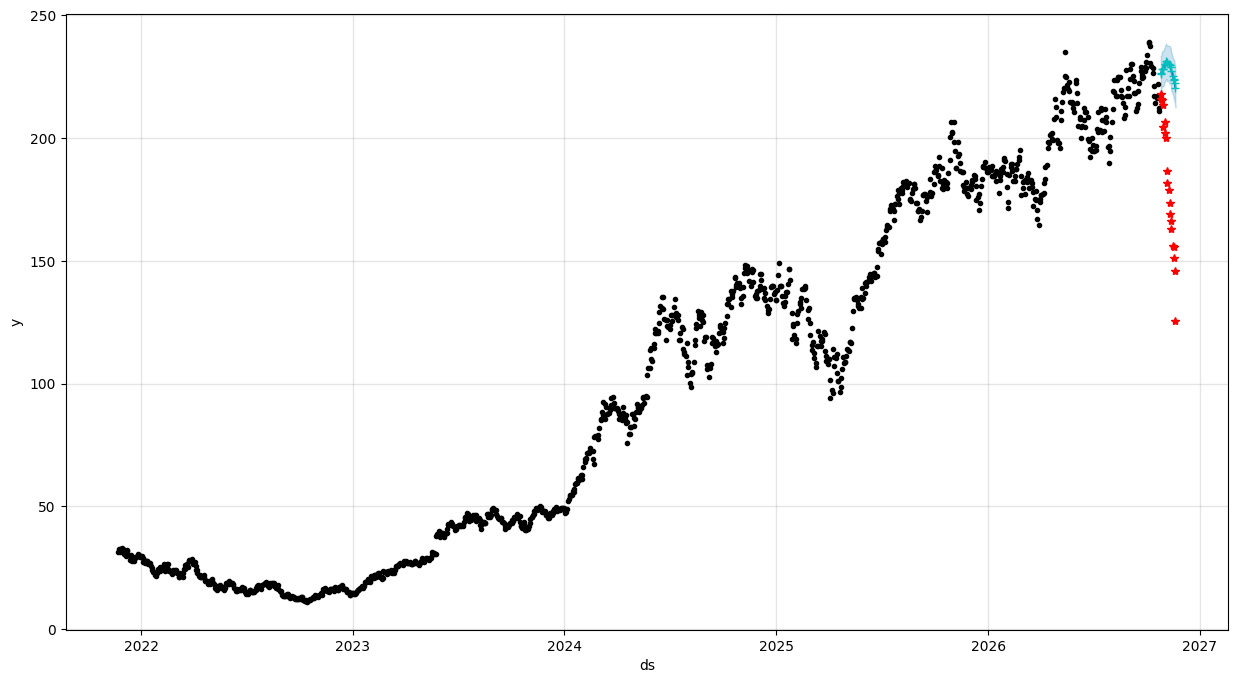

In [33]:
# La librería misma nos permite obtener las predicciones con las cotas mínima
# y máxima, además de su gráfica, como se muestra a continuación:

forecast = model.predict(test)

fig, ax = plt.subplots(figsize=(15, 8))
model.plot(forecast, ax=ax)               # Las predicciones se muestran con la línea continua, junto con su región de variabilidad de la predicción.
ax = plt.plot(test['ds'], test['y'], '*r')   # Agregamos los datos de prueba (Test) con puntos rojos, para observar la diferencia.
ax = plt.plot(test['ds'], forecast['yhat'], '+c')    # Valores reales.

#color rojo representan las predicciones
#color azul datos reales


# <font color=orange>**Interpretación Gráfica Facebook-Meta-Prophet**

-----------------------------------------------------------------------------

Puntos Rojos -> predicciones
Puntos azules -> Datos reales
parte sombreada -> intervalo de confianza de los datos

Se observa una tendencia alcista marcada en la serie hasta aproximarse al 2027, aunque luego las predicciones representadas por estrellas rojas caen fuerte por debajo de lo real y del rango de confianza, evidenciando un desajuste o quizás esa caída proyectada sea excesiva por parte de Prophet.



-----------------------------------------------------------------------------


# **4 - Long Short Term Memory (LSTM)**

# **DATOS ORIGINALES**

In [34]:
import tensorflow as tf

In [35]:
test.head()

,ds,y
1284,2026-10-26,216.000000
1285,2026-10-27,217.940002
1286,2026-10-28,215.380005
1287,2026-10-29,213.660004
1288,2026-10-30,204.639999


In [36]:
def preparando_datos(myData, myDate):

  # ++++++++ TRAIN +++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++

  # Los datos de entrenamiento son previos a la fecha "Date" que indiques y
  # tomarán hisotriales en este caso de 12 períodos previos.
  Train_Data = myData['y'][myData['ds'] < myDate].to_numpy()

  periodo = 12   # 12 meses al año

  Data_Train = []
  Data_Train_X = []
  Data_Train_Y = []

  for i in range(0, len(Train_Data), periodo):    # observa que va formando el Train set con historiales de 12 períodos consecutivos.
    try:
      Data_Train.append(Train_Data[i : i + periodo])
    except:
      pass


  # En ocasiones hay datos perdidos, en cuyo caso la última serie
  # de datos la eliminamos:
  if len(Data_Train[-1]) < periodo:
    Data_Train.pop(-1)


  # Hay que darle la forma (dimensionalidad) que requieren los modelos
  # de aprendizaje profundo, en particular la librería de TensorFlow:
  #     (batch_size, sequence_length, input_dimension).

  Data_Train_X = Data_Train[0 : -1]
  Data_Train_X = np.array(Data_Train_X)
  Data_Train_X = Data_Train_X.reshape((-1, periodo, 1))

  Data_Train_Y = Data_Train[1 : len(Data_Train)]
  Data_Train_Y = np.array(Data_Train_Y)
  Data_Train_Y = Data_Train_Y.reshape((-1, periodo, 1))


  # +++++++++++ TEST +++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++

  # Los datos de prueba (Test) son posteriores a la fecha "Date" y que es el
  # último ciclo que deseas predecir:
  Test_Data = myData['y'][myData['ds'] >= myDate].to_numpy()

  # inicialización de listas:
  Data_Test = []
  Data_Test_X = []
  Data_Test_Y = []

  for i in range(0, len(Test_Data), periodo):
    try:
      Data_Test.append(Test_Data[i : i + periodo])
    except:
      pass


  if len(Data_Test[-1]) < periodo:
    Data_Test.pop(-1)

  Data_Test_X = Data_Test[0 : -1]
  Data_Test_X = np.array(Data_Test_X)
  Data_Test_X = Data_Test_X.reshape((-1, periodo, 1))

  Data_Test_Y = Data_Test[1 : len(Data_Test)]
  Data_Test_Y = np.array(Data_Test_Y)
  Data_Test_Y = Data_Test_Y.reshape((-1, periodo, 1))


  return Data_Train_X, Data_Train_Y, Data_Test_X, Data_Test_Y


In [37]:
# Continuemos con el DataFrame como en Prophet:

threshold_Date = '2024-09-11'   # A partir de esta fecha se empieza a generar el Test.

# Recuerda que la columna de fechas del DataFrame df, debe ser de tipo DateTime.
# Se generan paquetes de 12 meses. Los *_Y son los años desfasados hacia adelante
# de los *_X:

Train_X, Train_Y, Test_X, Test_Y = preparando_datos(df_temp, threshold_Date)#aplica df temporal

In [38]:
# Podemos definir la manera en que el tamaño de paso (learning-rate) varíe
# en cada época. Es usual definir también algunas funciones, exponenciales,
# por ejemplo. Por el momento definamos valores constantes por intervalos:

def scheduler(epoch):

  if epoch <= 100:
    lrate = 0.05
  elif epoch <= 180:
    lrate = 0.0005
  elif epoch <=190:
    lrate = 0.00005
  else:
    lrate = (10 ** -5)

  return lrate


callback = tf.keras.callbacks.LearningRateScheduler(scheduler)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/200
2/2 ━━━━━━━━━━━━━━━━━━━━ 3s 533ms/step - loss: 2878.4885 - root_mean_squared_error: 53.6515 - val_loss: 17055.5742 - val_root_mean_squared_error: 130.5970 - learning_rate: 0.0500
Epoch 2/200
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 138ms/step - loss: 1942.5981 - root_mean_squared_error: 44.0749 - val_loss: 1103.6948 - val_root_mean_squared_error: 33.2219 - learning_rate: 0.0500
Epoch 3/200
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 146ms/step - loss: 880.6206 - root_mean_squared_error: 29.6753 - val_loss: 1799.7607 - val_root_mean_squared_error: 42.4236 - learning_rate: 0.0500
Epoch 4/200
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 119ms/step - loss: 251.8946 - root_mean_squared_error: 15.8712 - val_loss: 6467.1577 - val_root_mean_squared_error: 80.4186 - learning_rate: 0.0500
Epoch 5/200
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 138ms/step - loss: 229.4011 - root_mean_squared_error: 15.1460 - val_loss: 260.3742 - val_root_mean_squared_error: 16.1361 - learning_rate: 0.0500
Epoch 6/200
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 130ms/step - loss

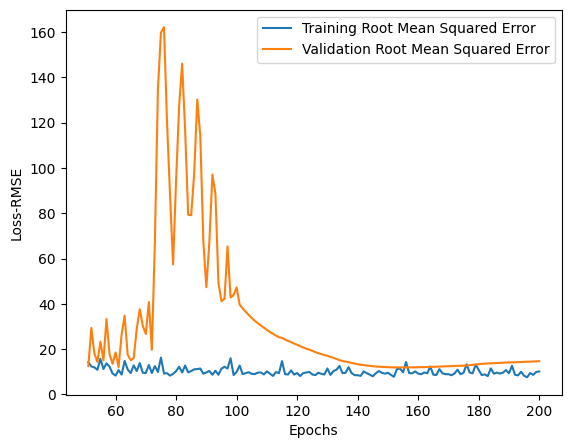

In [39]:
def myModel():

  model = tf.keras.models.Sequential([tf.keras.layers.LSTM(20, input_shape=(12, 1), activation=tf.nn.leaky_relu, return_sequences=True),
                                      tf.keras.layers.BatchNormalization(),
                                      tf.keras.layers.Dropout(0.2),
                                      #tf.keras.layers.LSTM(20, activation=tf.nn.leaky_relu),
                                      #tf.keras.layers.BatchNormalization(),
                                      #tf.keras.layers.Dropout(0.2),

                                      tf.keras.layers.Dense(200, activation=tf.nn.leaky_relu),
                                      tf.keras.layers.Dropout(0.2),
                                      #tf.keras.layers.Dense(120, activation=tf.nn.leaky_relu),


                                      tf.keras.layers.Dense(12, activation='linear')
                                      ])
  return model


# +++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++


my_LSTM_model2 = myModel()

my_LSTM_model2.compile(optimizer=tf.keras.optimizers.Adam(),
                      loss='mse',    # función de costo "mse"
                      metrics=[tf.keras.metrics.RootMeanSquaredError()]   #  RMSE- despliega
                      )


H = my_LSTM_model2.fit(Train_X,
                       Train_Y,
                       epochs=200,
                       validation_data=(Test_X, Test_Y),
                       callbacks=[callback],

                       )



N = 50  # Para omitir los N primeros valores en la gráfica, que en ocasiones son
        # demasiado grandes los errores y no dejan apreciar las curvas de aprendizaje.

epochs = range(N+1, len(H.history["loss"]) + 1)

fig, ax2 = plt.subplots()
fig.set_figheight(5)
ax2.plot(epochs, H.history["root_mean_squared_error"][N:], label = "Training Root Mean Squared Error")
ax2.plot(epochs, H.history["val_root_mean_squared_error"][N:], label = "Validation Root Mean Squared Error")
ax2.set(xlabel = "Epochs", ylabel = "Loss-RMSE")
ax2.legend()

plt.show()

In [40]:
pred_LSTM=my_LSTM_model2.predict(Test_X).reshape(-1)
pred_LSTM.shape

2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 258ms/step


(6624,)

In [41]:
# Calculamos el error RMSE:

pred_LSTM = H.model.predict(Test_X)
#pred_LSTM = my_LSTM_model2.predict(Test_X).reshape(-1)
pred_LSTM = pred_LSTM.reshape(-1)[-20:]  # Elegir los últimos 20 valores
rmse = np.sqrt(mean_squared_error(test['y'].values, pred_LSTM))

print('\nError-Modelo-FacebookProphet: RMSE: %.3f' % rmse)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step

Error-Modelo-FacebookProphet: RMSE: 33.938


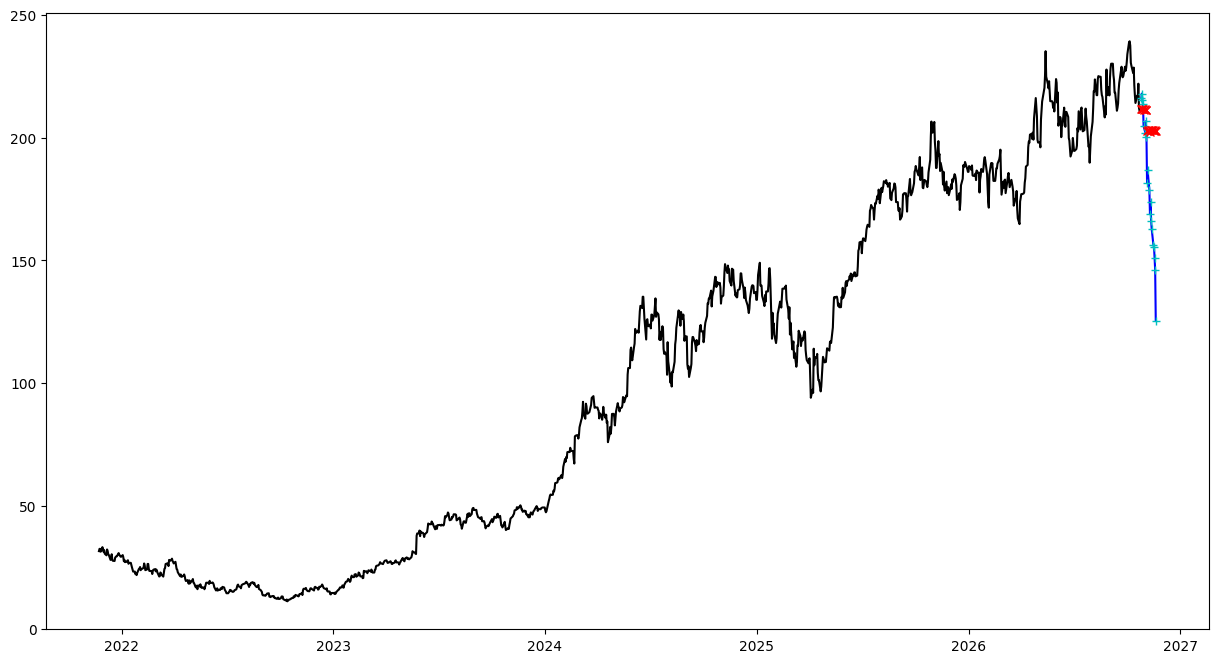

In [42]:
# Graficamos los resultados:
fig, ax = plt.subplots(figsize=(15, 8))
ax = plt.plot(train['ds'], train['y'], '-k')  # Datos de entrenamiento de 1949 a 1959.
ax = plt.plot(test['ds'], test['y'], '-b')    # Datos de prueba del año 1960.
ax = plt.plot(test['ds'], test['y'], '+c')    # Datos de prueba del año 1960.
ax = plt.plot(test['ds'], pred_LSTM, 'xr')  # Predicciones del modelo del año 1960.

**Habría que buscar la mejor arquitectura y ejecutarlo varias veces para obtener un mejor resultado.**

# <font color=orange>**Interpretación Gráfica Long Short Term Memory (LSTM)**

----------------------------------------------------------------------------
Las predicciones del modelo LSTM se mantuvieron alrededor de los 180 dólares, mientras que los precios reales presentaron cambios más pronunciados.

----------------------------------------------------------------------------

# <font color=orange>**Interpretación Valores RMSE Obtenidos de los modelos Ingenuo, ARIMA, Prophet y LSTM aplicado con Datos Orginales**</font>

-----------------------------------------------------------------------------

Los resultados obtenidos de RMSE, fueron los siguientes:

| # | Modelo  | Datos Originales RMSE |
|---|---------|-----------------------|
| 1 | Modelo Ingenuo (Baseline / Persistance / Naive model) |8.122 |
| 2 | Modelo ARIMA | 8.530 |
| 3 | Modelo Facebook-Meta-Prophet |52.453 |
| 4 | Long Short Term Memory (LSTM) | 33.938 |

**<font color=orange>INTERPRETACIÓN Y CONCLUSIÓN DE LA PRÁCTICA: </FONT>**

Durante el periodo analizado, el modelo Naive registro el error más bajo, siendo seguido por ARIMA que arrojo resultados similares. Por contraparte, LSTM no alcanzo a capturar la caída en precios, mientras Prophet mantuvo proyecciones superiores a los valores reales y termino con el mayor error. Es importante decir que estos resultados dependen de las condiciones del experimento. Además, Naive y ARIMA actualizaron sus predicciones con cada dato nuevo real, aunque Prophet hizo estimaciones para todo el periodo de prueba usando el modelo previamente ajustado.
---------------------------------------------------------------------------

++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++

# **A continuación, se aplicaran los mismos modelos planteados anteriormente (Ingenuo, ARIMA, Prophet y LSTM), pero aplicando escalamiento MinMaxScaler al conjunto de datos que estamos trabajando (ADJ-CLOSE).**

# **0 -PREPARACIÓN DATOS PARA ESCALAMIENTO**

# **DATOS ESCALADOS**

In [43]:
scaler = MinMaxScaler(feature_range=(0, 1))#aplica escalamiento rango 0,1

#Aplica Escalamiento a Entrenamiento y Prueba
train.loc[:, 'y_escalado'] = scaler.fit_transform(train[['y']])
test.loc[:, 'y_escalado']=scaler.transform(test[['y']])

/tmp/ipykernel_11886/2067651219.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  train.loc[:, 'y_escalado'] = scaler.fit_transform(train[['y']])
/tmp/ipykernel_11886/2067651219.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  test.loc[:, 'y_escalado']=scaler.transform(test[['y']])


In [44]:
train.head() #para visualizar nueva columna con los valores 'y' escalados

,ds,y,y_escalado
0,2021-11-23,31.606785,0.089541
1,2021-11-24,32.530712,0.093592
2,2021-11-25,32.530712,0.093592
3,2021-11-26,31.364849,0.088480
4,2021-11-29,33.229641,0.096657


In [45]:
#Elimina columna 'y' para quedarnos solo con las columnas: 'ds'  'y_escalado'
train_escalado=train.drop(columns=['y'])
test_escalado=test.drop(columns=['y'])

In [46]:
train_escalado.head()#verifica eliminacion columna 'y'

,ds,y_escalado
0,2021-11-23,0.089541
1,2021-11-24,0.093592
2,2021-11-25,0.093592
3,2021-11-26,0.088480
4,2021-11-29,0.096657


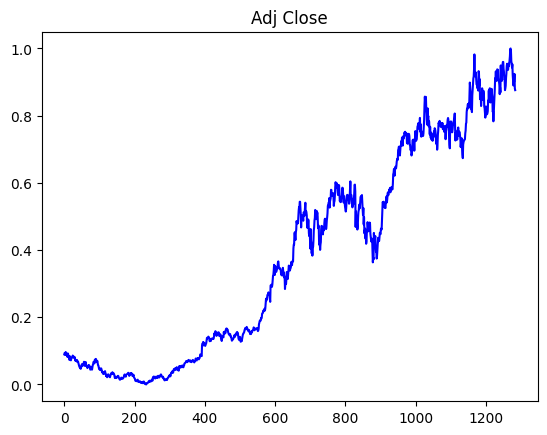

In [47]:
train_escalado['y_escalado'].plot(title='Adj Close', style='-b')
plt.show()

#<FONT COLOR=ORANGE>**Interpretación Gráfica. Comparativa con lo Obtenido en Datos Originales**

-----------------------------------------------------------------------------
El gráfico muestra la variable Adj Close escalada (normalizada entre 0 y 1) a lo largo de unos 1,300 registros, conservando exactamente la misma tendencia alcista global, fluctuaciones de corto plazo y retrocesos intermedios que la serie original en escala real (de ~10 a ~240), pero con la amplitud comprimida al rango [0, 1] para facilitar el entrenamiento de modelos sensibles a la escala (como redes neuronales).


-----------------------------------------------------------------------------

In [48]:
test_escalado['y_escalado'].values   #muestra valores del test con los datos escalados

array([0.89809397, 0.90660076, 0.89537532, 0.88783322, 0.84828104,
       0.83696789, 0.85727018, 0.82850499, 0.74725205, 0.76935212,
       0.73440414, 0.69151943, 0.71274252, 0.6796801 , 0.66503442,
       0.63561144, 0.63262971, 0.61289748, 0.59106043, 0.50138842])

# **1 - Modelo ingenuo (Baseline / Persistance / Naive model)**

# **DATOS ESCALADOS**

In [49]:
history = [x for x in train_escalado['y_escalado'].values]   # Definimos "history" donde de manera incremental se irán agregando registros mensuales.
predictions = list()    # Lista que contendrá las predicciones del modelo ingenuo.

for i in range(len(test_escalado['y_escalado'])):
  # Obtenemos las predicciones:
  yhat_scaled = history[-1]   # La primera vez, tomamos el último dato del Train, en las siguientes, se van agregando los datos de Test.
  predictions.append(yhat_scaled)

  # Observaciones-registros reales:
  obs_scaled = test_escalado.iloc[i]['y_escalado']   # Ahora vamos tomando los datos de Test.
  history.append(obs_scaled)  # Vamos agregando a "history" (que ya tiene todo los de Train) en cada iteración, un dato más de los de Test.
  print('>Esperado-real = %.3f, Predicción = %.3f' % (obs_scaled, yhat_scaled))


# Calculamos la raíz del error cuadrático medio (RMSE):
rmse = np.sqrt(mean_squared_error(test_escalado['y_escalado'].values, predictions))
print('\nError-Modelo-Naive con datos escalados: RMSE: %.3f' % rmse)

>Esperado-real = 0.898, Predicción = 0.876
>Esperado-real = 0.907, Predicción = 0.898
>Esperado-real = 0.895, Predicción = 0.907
>Esperado-real = 0.888, Predicción = 0.895
>Esperado-real = 0.848, Predicción = 0.888
>Esperado-real = 0.837, Predicción = 0.848
>Esperado-real = 0.857, Predicción = 0.837
>Esperado-real = 0.829, Predicción = 0.857
>Esperado-real = 0.747, Predicción = 0.829
>Esperado-real = 0.769, Predicción = 0.747
>Esperado-real = 0.734, Predicción = 0.769
>Esperado-real = 0.692, Predicción = 0.734
>Esperado-real = 0.713, Predicción = 0.692
>Esperado-real = 0.680, Predicción = 0.713
>Esperado-real = 0.665, Predicción = 0.680
>Esperado-real = 0.636, Predicción = 0.665
>Esperado-real = 0.633, Predicción = 0.636
>Esperado-real = 0.613, Predicción = 0.633
>Esperado-real = 0.591, Predicción = 0.613
>Esperado-real = 0.501, Predicción = 0.591

Error-Modelo-Naive con datos escalados: RMSE: 0.036


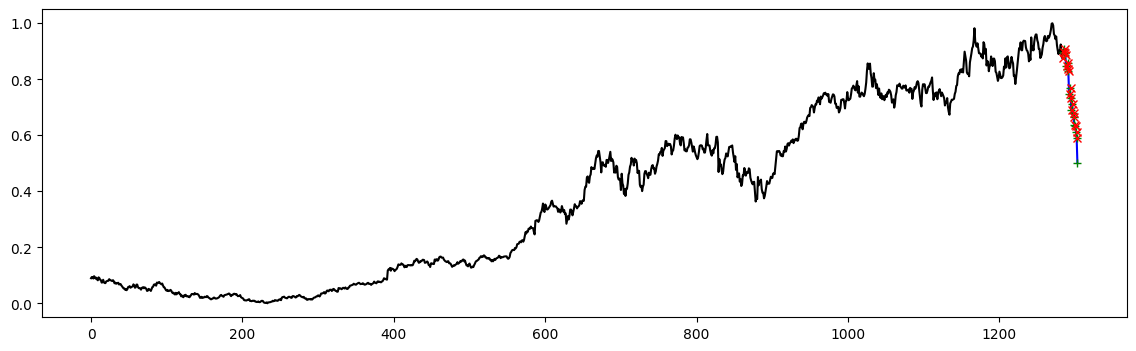

In [50]:
# Grafiquemos los resultados:

fig, ax = plt.subplots(figsize=(14, 4))
ax = plt.plot(train_escalado['y_escalado'], '-k')  # Datos de entrenamiento (los históricos).
ax = plt.plot(test_escalado['y_escalado'], '-b')    # Datos de prueba reales (los del útimo año a predecir).
ax = plt.plot(test_escalado['y_escalado'],'+g')
ax = plt.plot(test_escalado.index, predictions, 'xr')

#<FONT COLOR=ORANGE>**Interpretación Gráfica. Comparativa con lo obtenido en el modelo ingenuo con los datos originales**

----------------------------------------------------------------------------
El gráfico enseña las predicciones hechas sobre la serie escalada, test_escalado y las cruces rojas xr, justo en el tramo final después de una larga trayectoria que sube en la línea negra que llega casi a 1.0 antes de su caída. Al contrario de un modelo naive, el cual proyectaría el último valor observado o una continuación plana de la observación última, estas predicciones cae de forma muy pronunciada desde cerca de 0.9 hasta casi 0.58 mientras el marcador verde de símbolo más llega cerca de 0.50.


----------------------------------------------------------------------------

# **2 - Modelo ARIMA**
# **DATOS ESCALADOS**

In [51]:
#copia df con Conjunto Entrenamiento
train_escalado2=train_escalado.copy()
train_escalado2.head()

,ds,y_escalado
0,2021-11-23,0.089541
1,2021-11-24,0.093592
2,2021-11-25,0.093592
3,2021-11-26,0.088480
4,2021-11-29,0.096657


In [52]:
#copia df Conjunto de Prueba
test_escalado2=test_escalado.copy()
test_escalado2.head()

,ds,y_escalado
1284,2026-10-26,0.898094
1285,2026-10-27,0.906601
1286,2026-10-28,0.895375
1287,2026-10-29,0.887833
1288,2026-10-30,0.848281


In [53]:
train_escalado2 = train_escalado2.set_index('ds') #Aplica ds como índice en conjunto entrenamiento

In [54]:
test_escalado2 =test_escalado2.set_index('ds')   #Aplica ds como índice en conjunto de Prueba

In [55]:
train_escalado2.head()  #Verifica datos escalados Entrenamiento

,y_escalado
ds,
2021-11-23,0.089541
2021-11-24,0.093592
2021-11-25,0.093592
2021-11-26,0.088480
2021-11-29,0.096657


In [56]:
test_escalado2.head() #Verificar datos Escalados Prueba

,y_escalado
ds,
2026-10-26,0.898094
2026-10-27,0.906601
2026-10-28,0.895375
2026-10-29,0.887833
2026-10-30,0.848281


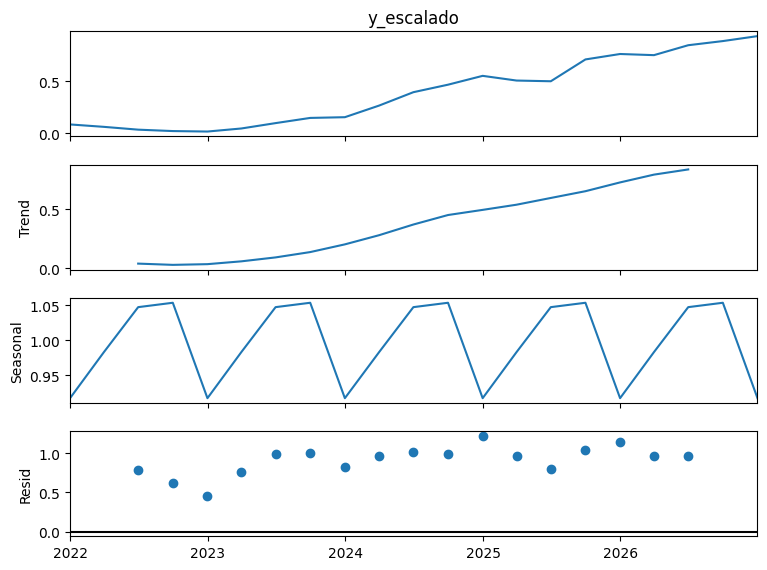

In [57]:
# Gráficos de descomposición estacional con datos escalados:
decomposition = seasonal_decompose(train_escalado2['y_escalado'].resample('QE').mean(), model='multiplicative')  # <<<---- Observa que el modelo es multiplicativo
fig = decomposition.plot()
fig.set_size_inches(8,6)
plt.show()

# <FONT COLOR=ORANGE>**Interpretación Gráfica. Compartiva con Datos Originales**



------------------------------------------------------------------------
La descomposición de y_escalado (2022–2026/2027) muestra una tendencia (Trend) suavizada y creciente de ~0.05 a ~0.85, un patrón estacional (Seasonal) multiplicativo repetitivo entre ~0.92 y ~1.06 (con mínimos cerca de los cambios de año y picos intermedios) y residuos (Resid) centrados alrededor de 1.0 (con algunas variaciones entre ~0.45 y ~1.2). En comparación con los datos originales, la estructura de fondo es la misma —un crecimiento sostenido de 2022 a 2026 con oscilaciones periódicas—, pero al estar escalada en [0, 1] y agregada/descompuesta de forma más suave, se atenúa el ruido diario y los retrocesos bruscos de corto plazo visibles en la serie original


--------------------------------------------------------------------------

/tmp/ipykernel_11886/2789695146.py:2: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  fig = month_plot(train_escalado2['y_escalado'].resample('M').mean(), ylabel='Adj_Close')


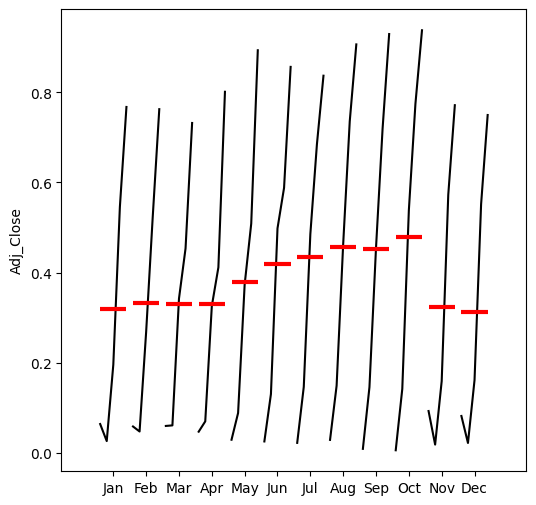

In [58]:
# Gráfica para detección de estacionalidad mensual con datos escalados:
fig = month_plot(train_escalado2['y_escalado'].resample('M').mean(), ylabel='Adj_Close')
fig.set_size_inches(6,6)
plt.show()

/tmp/ipykernel_11886/3518444989.py:2: FutureWarning: 'Q' is deprecated and will be removed in a future version, please use 'QE' instead.
  fig = quarter_plot(train_escalado2['y_escalado'].resample('Q').mean(), ylabel='Adj_Close')


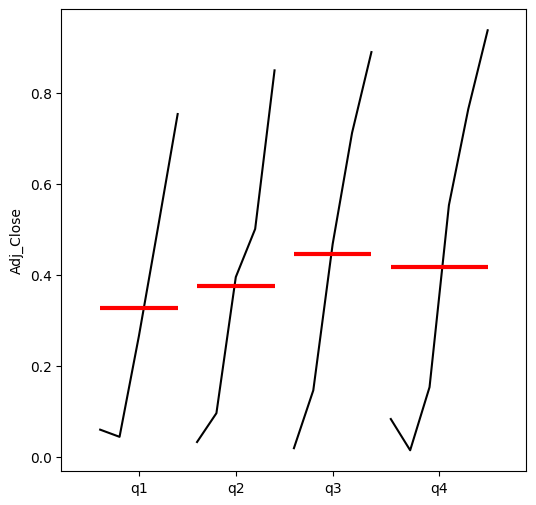

In [59]:
# Si queremos graficar y detectar estacionalidad trimestral con datos escalados:
fig = quarter_plot(train_escalado2['y_escalado'].resample('Q').mean(), ylabel='Adj_Close')
fig.set_size_inches(6,6)
plt.show()

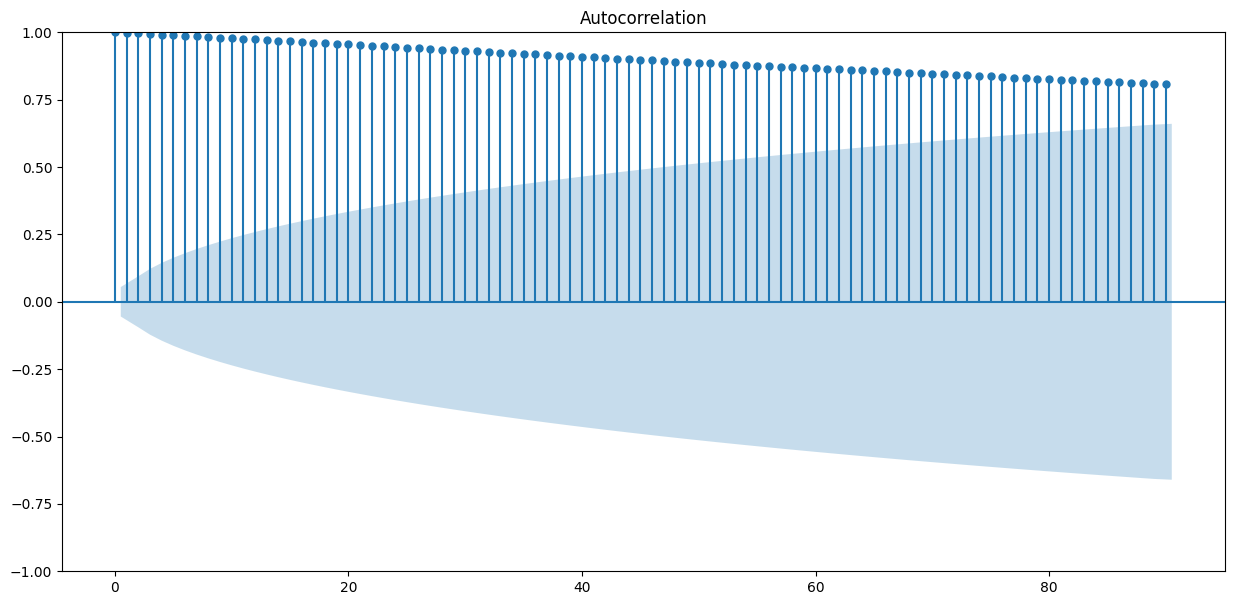

In [60]:
# Gráfico de Autocorrelación (ACF: Auto-Correlation-Function) con datos escalados
fig,ax = plt.subplots(figsize = (15,7))
plot_acf(train_escalado2['y_escalado'], lags = 90,ax=ax)   # Eliges el número de unidades (meses) desfasadas. El número de "lags" es el número
plt.show()                          # que define la partición en el eje horizontal. El área no sombreada nos habla de
                                    # la cantidad de períodos de tiempo hacia atrás cuya información proporcionada es
                                    # significativa para la predicción futura.


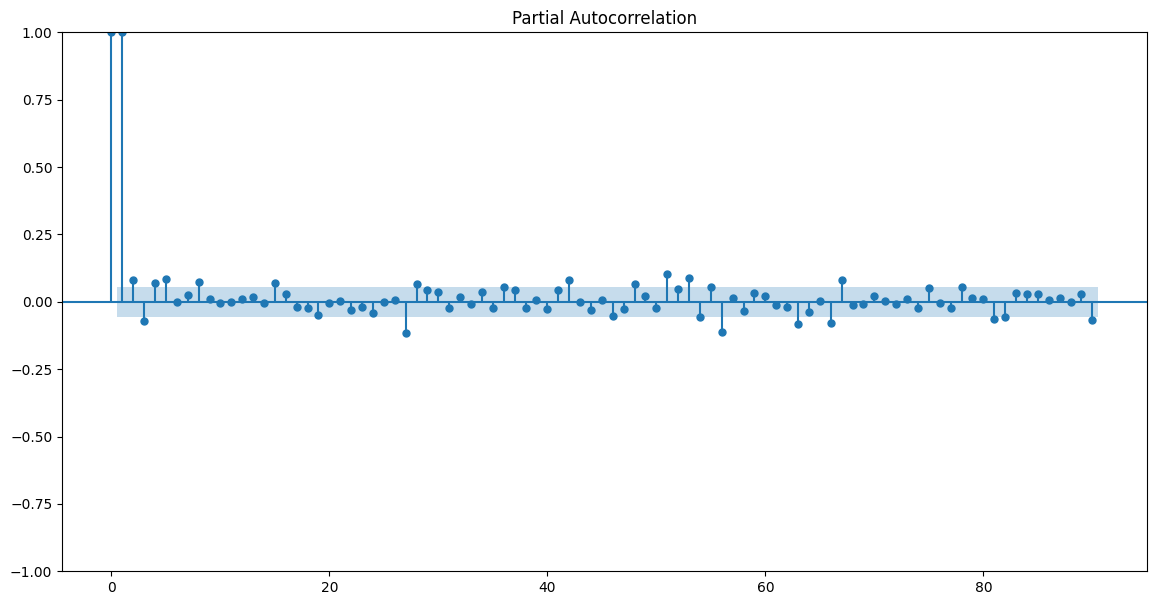

In [61]:
# Gráfico de Autocorrelación Parcial (PACF) con datos escalados:
fig, ax = plt.subplots(figsize = (14,7))
plot_pacf(train_escalado2['y_escalado'], lags = 90, ax = ax, method="ols")   # ols: regression of time series on lags of it an on constant. predetrminado method="ywm"
plt.show()

In [62]:
# Definamos la siguiente lista de registros de Adj Close en el tiempo con datos escalados:
history_escalado = [x for x in train_escalado2.loc[:,'y_escalado'].values]   # train-ndarray : columna solo con los registros de Adj Close "y".
                               # history-list : lista con los datos del train.

predictions_escalado = list()   # Para incluir las predicciones que vaya generando el modelo.

for i in range(len(test_escalado2['y_escalado'])):
  #
  months_in_year = 12
  diff = difference(history_escalado, months_in_year)    # diff-list: lista de los datos de diferencias para transformar SARIMA en ARIMA.

  # Generamos el modelo.
  model_escalado = ARIMA(diff, order=(1,0,5),) # Si aplicamos diff, entonces d=0 es aplicable.
  model_fit_escalado = model_escalado.fit(method_kwargs={'maxiter':500})  # Aumentar las iteraciones para evitar el WarningConvergence.

  yhat_escalado = model_fit_escalado.forecast()[0]   # prediccions (yhat) de cada registro, es un solo número flotante.
  yhat_escalado = inverse_difference(history_escalado, yhat_escalado, months_in_year)    # El "history" sigue siendo la lista de arriba.
                                                              # El nuevo "yhat" es cada un nuevo valor (float) de predicción.
  predictions_escalado.append(yhat_escalado)  # predictions-list : lista que se va incrementando al ir agregando cada predicción nueva.

  # Observaciones-reales:
  obs_escalado = test_escalado2.iloc[i]['y_escalado']   #  cada dato es un flotante.
  history_escalado.append(obs_escalado)   #  history-list : se va incrementado a partir del Train con los registros-observaciones reales.

  print('>Esperado-real = %.3f, Predicción = %.3f' % (obs_escalado, yhat_escalado))

# Error RMSE:
rmse = np.sqrt(mean_squared_error(test_escalado2['y_escalado'].values, predictions_escalado))
print('\nError-Modelo-ARIMA: RMSE: %.3f' % rmse)

>Esperado-real = 0.898, Predicción = 0.855
>Esperado-real = 0.907, Predicción = 0.903
>Esperado-real = 0.895, Predicción = 0.912
>Esperado-real = 0.888, Predicción = 0.912
>Esperado-real = 0.848, Predicción = 0.865
>Esperado-real = 0.837, Predicción = 0.842
>Esperado-real = 0.857, Predicción = 0.833
>Esperado-real = 0.829, Predicción = 0.876
>Esperado-real = 0.747, Predicción = 0.841
>Esperado-real = 0.769, Predicción = 0.785
>Esperado-real = 0.734, Predicción = 0.736
>Esperado-real = 0.692, Predicción = 0.754
>Esperado-real = 0.713, Predicción = 0.739
>Esperado-real = 0.680, Predicción = 0.734
>Esperado-real = 0.665, Predicción = 0.696
>Esperado-real = 0.636, Predicción = 0.682
>Esperado-real = 0.633, Predicción = 0.622
>Esperado-real = 0.613, Predicción = 0.643
>Esperado-real = 0.591, Predicción = 0.662
>Esperado-real = 0.501, Predicción = 0.588

Error-Modelo-ARIMA: RMSE: 0.044


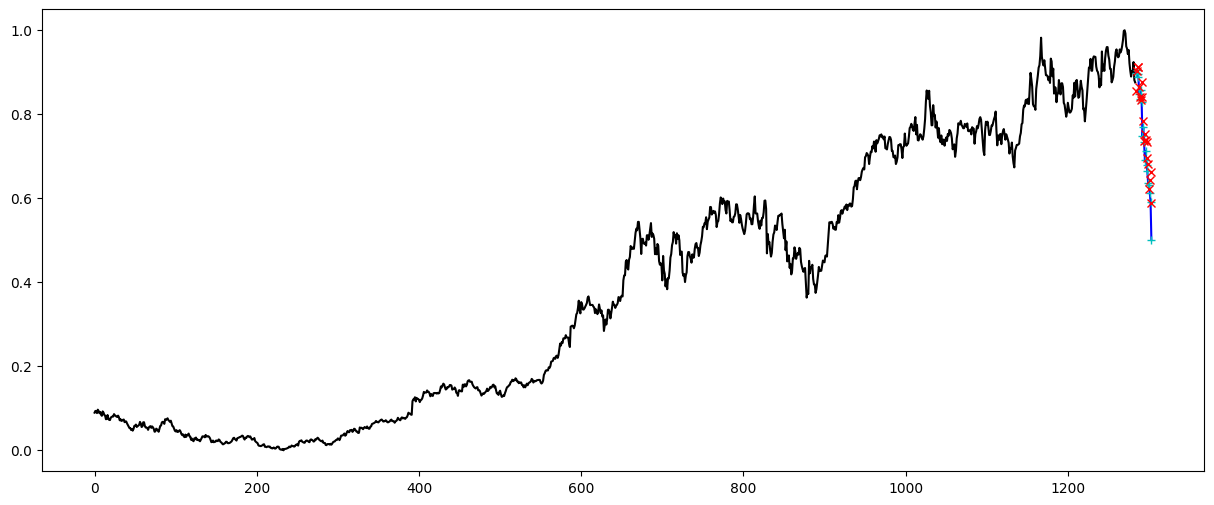

In [63]:
# Veamos su gráfico:
fig, ax = plt.subplots(figsize=(15, 6))
ax = plt.plot(train_escalado['y_escalado'], '-k')
ax = plt.plot(test_escalado['y_escalado'], '-b')
ax = plt.plot(test_escalado['y_escalado'], '+c')
ax = plt.plot(test_escalado.index, predictions_escalado, 'xr')

# **3 - Modelo Facebook-Meta-Prophet**
# **DATOS ESCALADOS**

In [64]:
df_temp_escalado=df_temp.copy() #copia en nuevo df
df_temp_escalado.head()

,ds,y
0,2021-11-23,31.606785
1,2021-11-24,32.530712
2,2021-11-25,32.530712
3,2021-11-26,31.364849
4,2021-11-29,33.229641


In [65]:
df_temp_escalado= df_temp_escalado.rename(columns={'Date':'ds','y_escalado':'y'})
df_temp_escalado.head()

,ds,y
0,2021-11-23,31.606785
1,2021-11-24,32.530712
2,2021-11-25,32.530712
3,2021-11-26,31.364849
4,2021-11-29,33.229641


In [66]:
train_escalado = df_temp_escalado.iloc[0:-20,:] #partición Entrenamiento. Todos menos los últimos 20 registros
test_escalado = df_temp_escalado.iloc[-20:,:] #partición Prueba. Solo los últimos 20 registros

In [67]:
#Aplica Escalamiento MinMaxScaler a entrenamiento y prueba
scaler = MinMaxScaler(feature_range=(0, 1))
train_escalado.loc[:, 'y']=scaler.fit_transform(train_escalado[['y']])
test_escalado.loc[:, 'y']=scaler.transform(test_escalado[['y']])

In [68]:
train_escalado.head()

,ds,y
0,2021-11-23,0.089541
1,2021-11-24,0.093592
2,2021-11-25,0.093592
3,2021-11-26,0.088480
4,2021-11-29,0.096657


In [69]:
# Aplicamos el modelo Facebbok-Prophet a nuestros datos:

model_escalado = Prophet(seasonality_mode='multiplicative',
                yearly_seasonality=True,
                changepoint_prior_scale=10.,   # Controla la flexibilidad de la componente Trend, mayor valor mayores fluctuaciones.
                seasonality_prior_scale=30,)   # Controla la estacionalidad, mayor el valor, mayor flexibilidad en la estacionalidad.
model_escalado.fit(train_escalado)

INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


In [70]:
# Calculamos el error RMSE con datos escalados:
pred_FP_escalado = model_escalado.predict(test_escalado)['yhat']
rmse = np.sqrt(mean_squared_error(test_escalado['y'], pred_FP_escalado))
print('\nError-Modelo-FacebookProphet con datos escalados: RMSE: %.3f' % rmse)


Error-Modelo-FacebookProphet con datos escalados: RMSE: 0.229


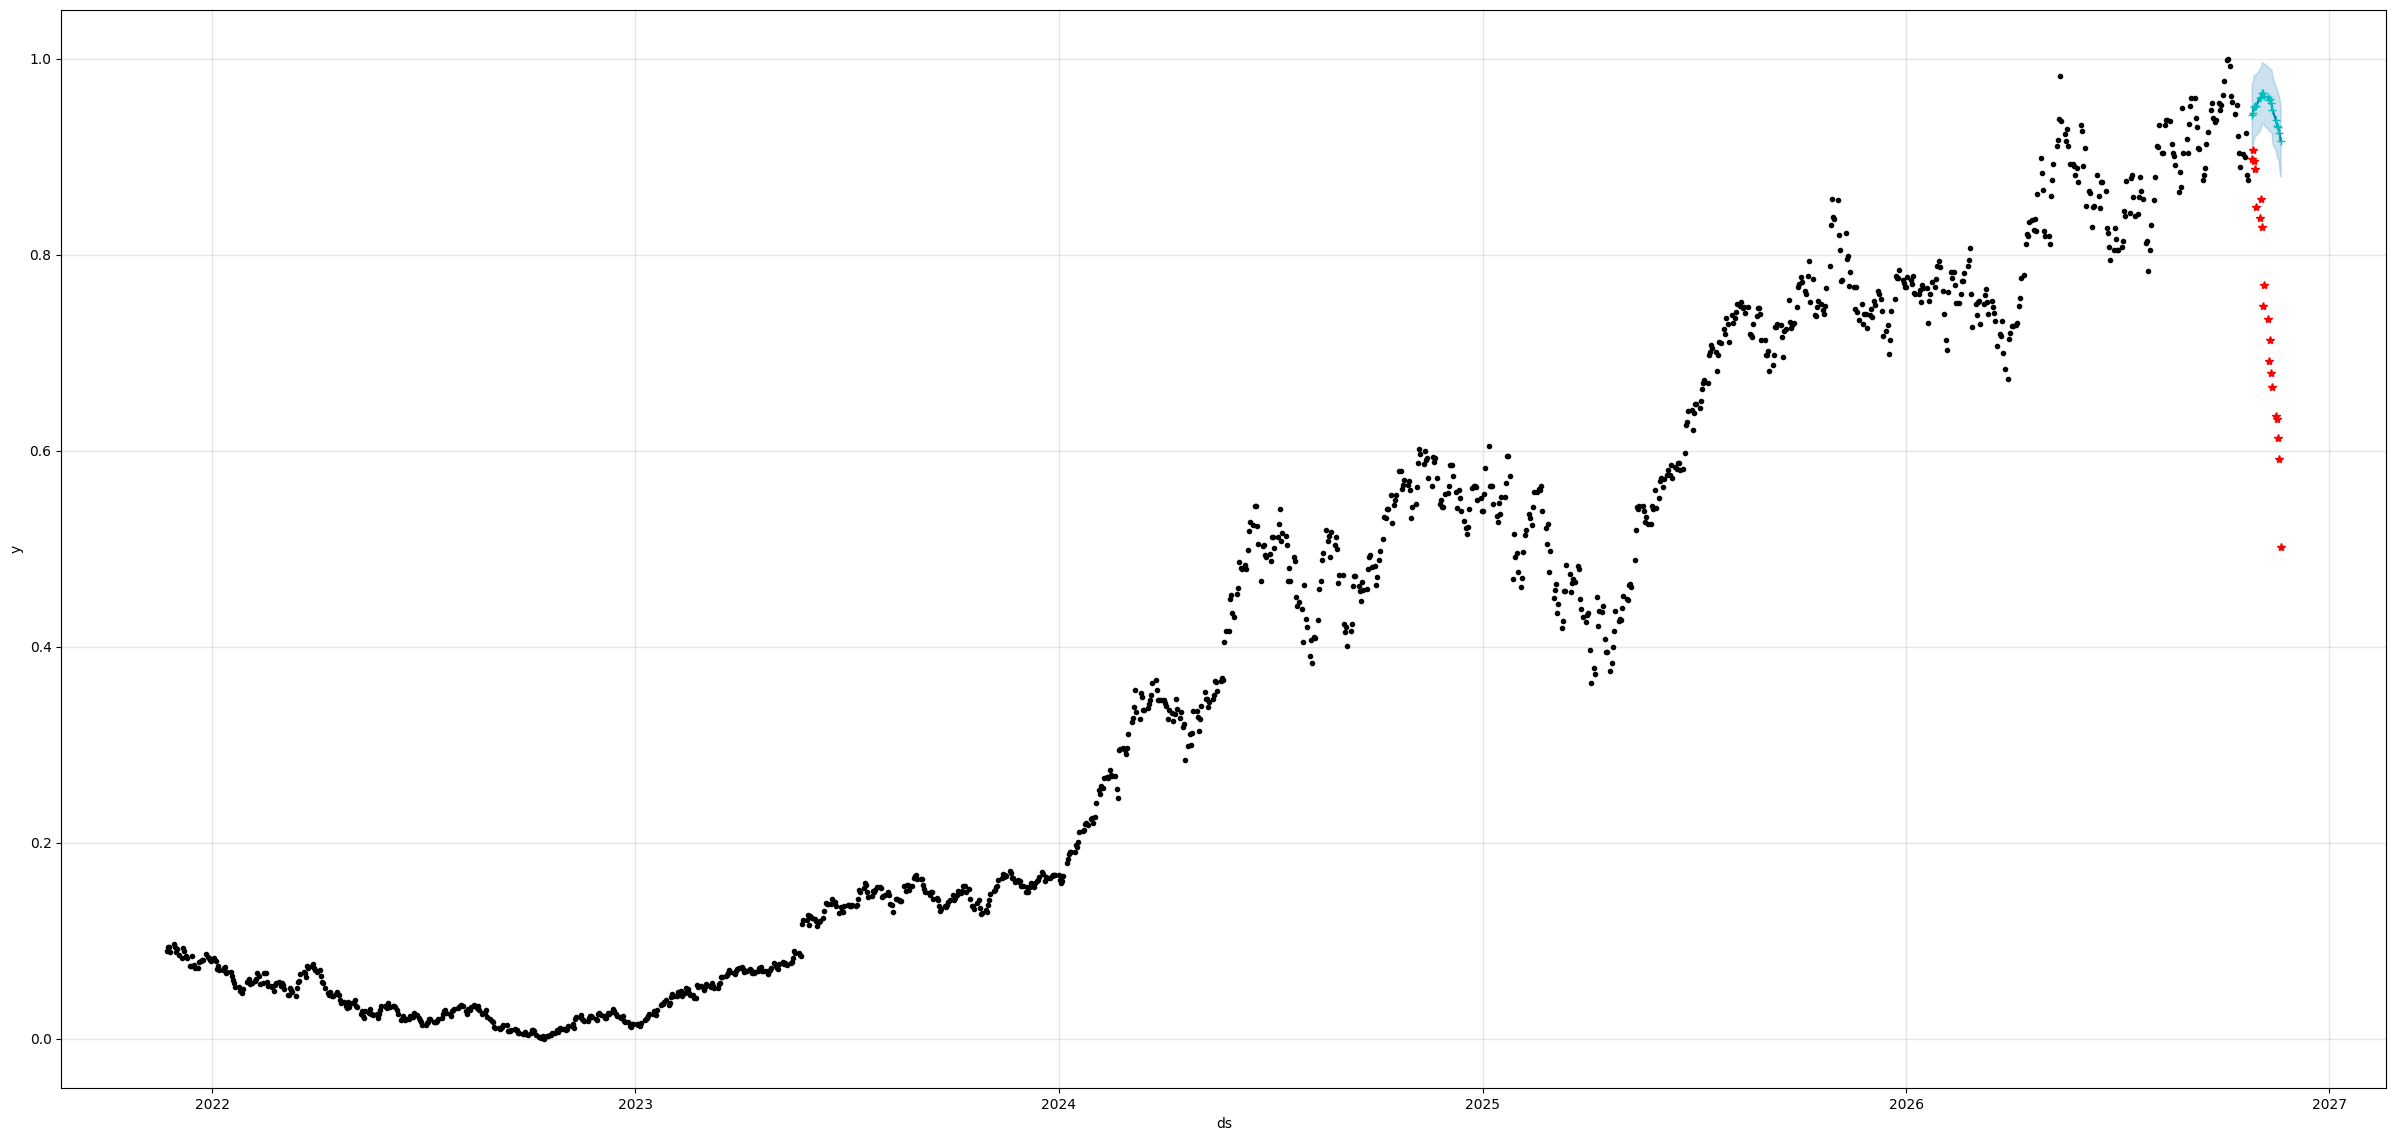

In [71]:
# La librería misma nos permite obtener las predicciones con las cotas mínima
# y máxima, además de su gráfica, como se muestra a continuación:

forecast_escalado = model_escalado.predict(test_escalado)

fig, ax = plt.subplots(figsize=(30, 14))
model_escalado.plot(forecast_escalado, ax=ax)       # Las predicciones se muestran con la línea continua, junto con su región de variabilidad de la predicción.
ax = plt.plot(test_escalado['ds'], test_escalado['y'], '*r') # Agregamos los datos de prueba (Test) con puntos rojos, para observar la diferencia.
ax = plt.plot(test_escalado['ds'], forecast_escalado['yhat'], '+c')  # Valores reales.

# **4 - Long Short Term Memory (LSTM)**

# **DATOS ESCALADOS**

In [72]:
test_escalado.head()

,ds,y
1284,2026-10-26,0.898094
1285,2026-10-27,0.906601
1286,2026-10-28,0.895375
1287,2026-10-29,0.887833
1288,2026-10-30,0.848281


In [73]:
df_temp_escalado.head()

,ds,y
0,2021-11-23,0.089541
1,2021-11-24,0.093592
2,2021-11-25,0.093592
3,2021-11-26,0.088480
4,2021-11-29,0.096657


In [74]:
# Continuemos con el DataFrame como en Prophet:

threshold_Date_escalado = '2024-09-24'   # A partir de esta fecha se empieza a generar el Test.

# Recuerda que la columna de fechas del DataFrame df, debe ser de tipo DateTime.
# Se generan paquetes de 12 meses. Los *_Y son los años desfasados hacia adelante
# de los *_X:

Train_X, Train_Y, Test_X, Test_Y = preparando_datos(df_temp_escalado, threshold_Date_escalado)

In [75]:
def myModel():

  model = tf.keras.models.Sequential([tf.keras.layers.LSTM(200, input_shape=(12, 1), activation=tf.nn.leaky_relu, return_sequences=True),
                                      tf.keras.layers.BatchNormalization(),
                                      tf.keras.layers.Dropout(0.4),
                                      #tf.keras.layers.LSTM(20, activation=tf.nn.leaky_relu),
                                      #tf.keras.layers.BatchNormalization(),
                                      #tf.keras.layers.Dropout(0.2),

                                      tf.keras.layers.Dense(200, activation=tf.nn.leaky_relu),
                                      tf.keras.layers.Dropout(0.4),
                                      #tf.keras.layers.Dense(120, activation=tf.nn.leaky_relu),


                                      tf.keras.layers.Dense(12, activation='linear')
                                      ])
  return model

In [76]:
def scheduler(epoch):
    if epoch <= 50:
        return 0.05
    elif epoch <= 100:
        return 0.01
    elif epoch <= 150:
        return 0.001
    else:
        return 0.0001

callback = tf.keras.callbacks.LearningRateScheduler(scheduler)

Epoch 1/200


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


2/2 ━━━━━━━━━━━━━━━━━━━━ 4s 638ms/step - loss: 1.1212 - root_mean_squared_error: 1.0589 - val_loss: 2.0901 - val_root_mean_squared_error: 1.4457 - learning_rate: 0.0500
Epoch 2/200
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 194ms/step - loss: 7.1130 - root_mean_squared_error: 2.6670 - val_loss: 0.1753 - val_root_mean_squared_error: 0.4187 - learning_rate: 0.0500
Epoch 3/200
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 188ms/step - loss: 1.2118 - root_mean_squared_error: 1.1008 - val_loss: 0.1461 - val_root_mean_squared_error: 0.3822 - learning_rate: 0.0500
Epoch 4/200
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 199ms/step - loss: 1.0458 - root_mean_squared_error: 1.0227 - val_loss: 0.2469 - val_root_mean_squared_error: 0.4969 - learning_rate: 0.0500
Epoch 5/200
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 113ms/step - loss: 0.7237 - root_mean_squared_error: 0.8507 - val_loss: 1.3857 - val_root_mean_squared_error: 1.1771 - learning_rate: 0.0500
Epoch 6/200
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 113ms/step - loss: 1.1019 - root_mean_squared_error: 1.0497 - val_l

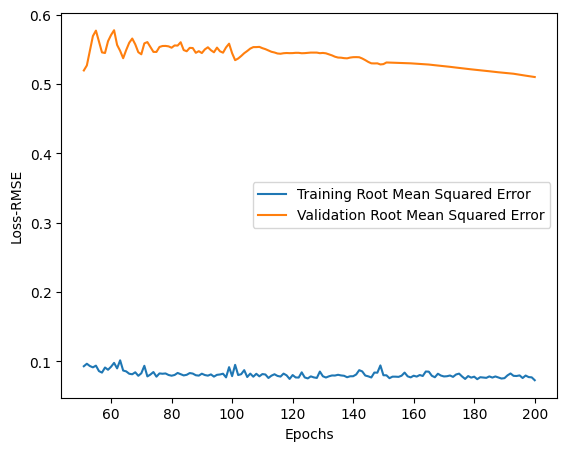

In [77]:

# +++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++


my_LSTM_model2 = myModel()

my_LSTM_model2.compile(optimizer=tf.keras.optimizers.Adam(),
                      loss='mse',    # función de costo "mse"
                      metrics=[tf.keras.metrics.RootMeanSquaredError()]   #  RMSE- despliega
                      )


H = my_LSTM_model2.fit(Train_X,
                       Train_Y,
                       epochs=200,
                       validation_data=(Test_X, Test_Y),
                       callbacks=[callback],

                       )



N = 50  # Para omitir los N primeros valores en la gráfica, que en ocasiones son
        # demasiado grandes los errores y no dejan apreciar las curvas de aprendizaje.

epochs = range(N+1, len(H.history["loss"]) + 1)

fig, ax2 = plt.subplots()
fig.set_figheight(5)
ax2.plot(epochs, H.history["root_mean_squared_error"][N:], label = "Training Root Mean Squared Error")
ax2.plot(epochs, H.history["val_root_mean_squared_error"][N:], label = "Validation Root Mean Squared Error")
ax2.set(xlabel = "Epochs", ylabel = "Loss-RMSE")
ax2.legend()

plt.show()

In [78]:
#pred_LSTM = H.model.predict(Test_X) scaled
pred_LSTM_escalado = my_LSTM_model2.predict(Test_X).reshape(-1)
pred_LSTM_escalado.shape

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 181ms/step


(6624,)

In [79]:
# Calculamos el error RMSE con datos escalados:

pred_LSTM_escalado = H.model.predict(Test_X)
#pred_LSTM = my_LSTM_model2.predict(Test_X).reshape(-1)

pred_LSTM_escalado = pred_LSTM_escalado.reshape(-1)[-20:]  # Select the last 20 values
rmse = np.sqrt(mean_squared_error(test_escalado['y'].values, pred_LSTM_escalado))

print('\nError-Modelo-FacebookProphet con datos escalados: RMSE: %.3f' % rmse)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step

Error-Modelo-FacebookProphet con datos escalados: RMSE: 0.561


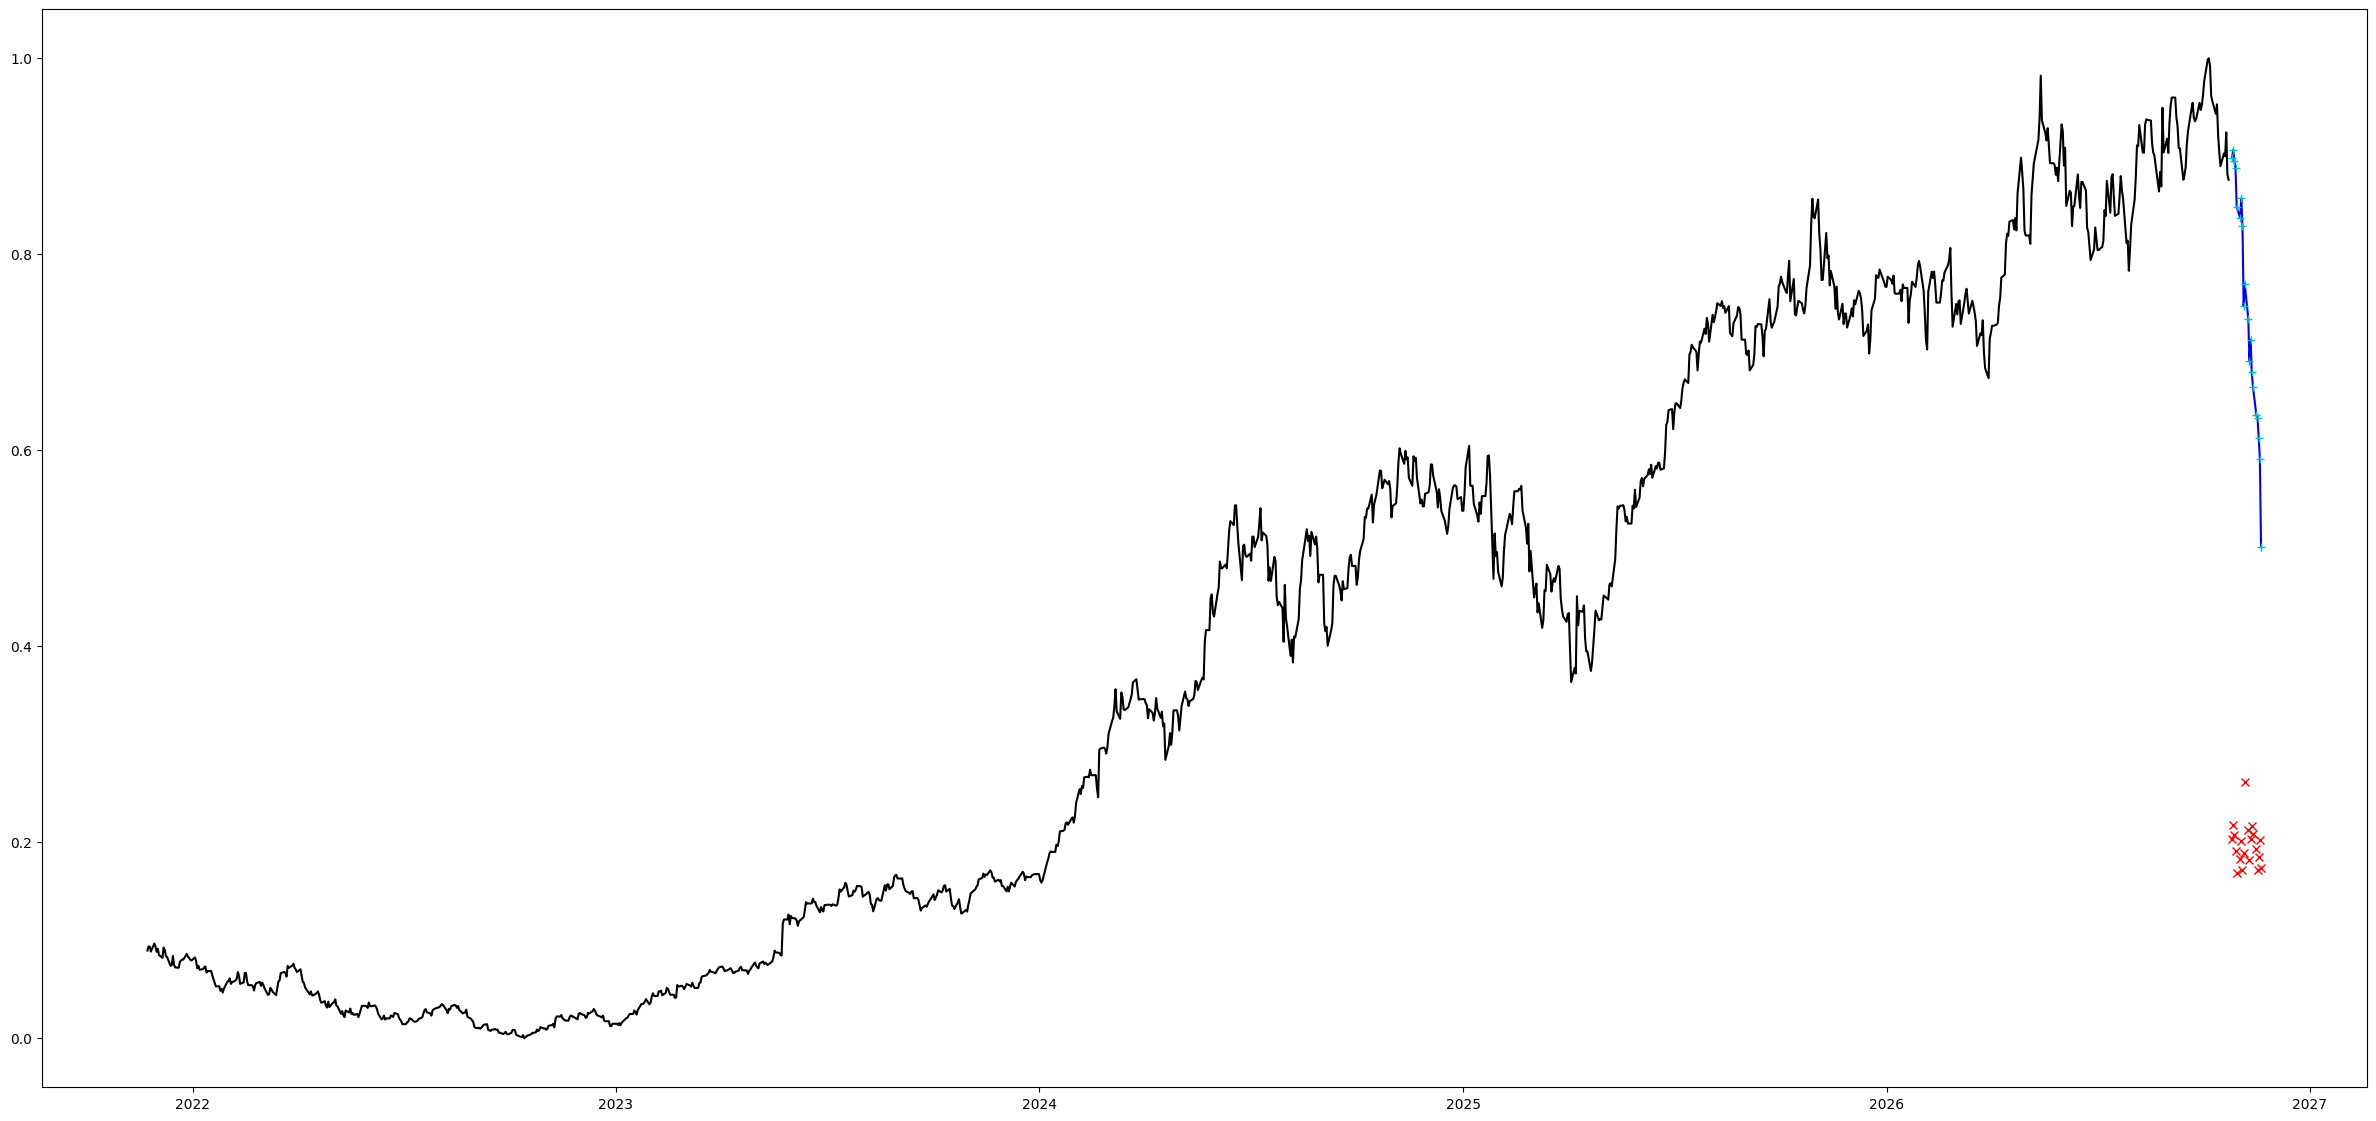

In [80]:
# Graficamos los resultados:
fig, ax = plt.subplots(figsize=(30, 14))
ax = plt.plot(train_escalado['ds'], train_escalado['y'], '-k')  # Datos de entrenamiento de 1949 a 1959.
ax = plt.plot(test_escalado['ds'], test_escalado['y'], '-b')    # Datos de prueba del año 1960.
ax = plt.plot(test_escalado['ds'], test_escalado['y'], '+c')    # Datos de prueba del año 1960.
ax = plt.plot(test_escalado['ds'], pred_LSTM_escalado, 'xr')

# **CONCLUSIÓN DE LA ACTIVIDAD**


----------------------------------------------------------------------------
# **¿Consideras que el escalamiento de los datos ayude a obtener mejores predicciones? Justifica tu respuesta.**
Escalar datos permite ajustar valores para simplificar el procesamiento en ciertos modelos, pero ojo, esto no garantiza mejores predicciones. En esta práctica al aplicar Min Max los valores cambiaron su escala y por lo tanto también la unidad del RMSE se modificó. Para hacer una comparación adecuada se necesita considerar los resultados expresado en dólares usando siempre el mismo periodo de evaluación.


### **Modelo Ingenuo**
Tras aplicar el escalamiento el comportamiento predictivo permaneció igual dado que este modelo siempre emplea el último dato registrado para calcular el siguiente. Donde si hubo diferencia fue en el RMSE el cual pasó de 7011 a 0031 dólares usando los datos normalizados. Esto sucede porque los valores fueron transformado a una escala diferente.


### **Modelo ARIMA**
El modelo ARIMA ha mostrado comportamientos parecidos al usar datos originales o escalados. Pudo representar la tendencia descendente en los precios durante los dos casos, pese a que algunas predicciones quedaron sobre los valores reales. El escalamiento no produjo una diferencia grande en la precisión de los resultados.



### **Modelo Facebook-Meta-Prophet**
Al cotejar ambas versiones, Prophet sigue mostrando predicciones algo elevadas, pues no se adapta bien a la bajada en los precios reales. Esto demuestra que la normalización no resulta suficiente para que mejore su capacidad de anticipar los cambios durante el periodo evaluado.


### **Modelo Long Short Term Memory (LSTM)**
El modelo LSTM mostró problemas para capturar las variaciones de precios correctamente. Sus predicciones se estancaron en un mismo nivel, ignorando totalmente la caída real de los datos. En la versión escalada, es fundamental que tanto la entrada como las predicciones compartan la misma escala al compararlas. Por eso, hace falta una evaluación extra para ver si la normalización mejora el desempeño de esta red neuronal.


A continación se muestra una tabla comparativa con los valores RMSE de datos originales y datos escalados de cada uno de los modelos:


| # | Modelo  | Datos Originales RMSE | Datos Escalados RMSE |
|---|---------|-----------------------|----------------------|
| 1 | Modelo Ingenuo (Baseline / Persistance / Naive model) | 8.122 | 0.036 |
| 2 | Modelo ARIMA | 8.530 | 0.044 |
| 3 | Modelo Facebook-Meta-Prophet | 52.453 | 0.229 |
| 4 | Long Short Term Memory (LSTM) | 33.938 | 0.561 |

------------------------------------------------------------------------
# **INTERPRETACION de resultados RMSE**


### **RMSE DATOS ORIGINALES**

Trabajando con los datos base, el modelo Ingenuo logró el menor error en 8122, luego viene ARIMA con 8530, lo cual señala que estos dos modelos tuvieron un desempeño superior al predecir. Por otra parte, LSTM presenta un error de 33938, mientras que el valor más alto fue de Facebook Meta Prophet con 52453, marcando una diferencia mayor entre los datos reales y estimados.

++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++

### **RMSE DATOS ESCALADOS**

Tras escalar los datos, el modelo Ingenuo presentó el error más bajo con 0 036, seguido de ARIMA por 0 044. Un RMSE de 0 229 fue lo obtenido por Prophet, mientras LSTM registró el error más alto siendo 0 561. Esto demuestra que los modelos Ingenuo y ARIMA conservaron los mejores resultados en la escala normalizada.





+++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++

# **En conclusión:**

Al cotejar los resultados, se observa que el modelo Ingenuo presenta la mayor precisión, tanto con los datos originales como con los escalados. ARIMA también obtuvo resultados favorables, manteniéndose bastante cerca del Ingenuo. Por otra parte, Prophet y LSTM registraron errores más elevados. Es importante notar que los valores RMSE escalados están expresados en otra escala, por lo que no se deben comparar directamente con los originales. En general, los modelos Ingenuo y ARIMA fue los que mejor se ajustaron a los datos durante esta práctica.




------------------------------------------------------------------------

# **Referencias Bibliográficas**

Norton, V. (2011). Adjusted closing prices. arXiv preprint arXiv:1105.2956.

Luo, Y. X., & Ji, Y. (2022, September). Prediction of the Stock Adjusted Closing Price Based On Improved PSO-LSTM Neural Network. In 2022 International Conference on Machine Learning and Cybernetics (ICMLC) (pp. 43-48). IEEE.

Wijaya, A. C., Kusumaningrum, R., Sugiharto, A., & Aryotejo, G. (2024, July). Prophet Algorithm Optimization with Particle Swarm Optimization for Adjusted Closing Price Forecasting in Xiaomi Corporation. In 2024 7th International Conference on Informatics and Computational Sciences (ICICoS) (pp. 376-381). IEEE.


----------------------------------------------------------------------------

>> ## **Fin del Ejercicio de Series de Tiempo**